# **Import**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/dog_adoption_master.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   adoption_id             42000 non-null  object 
 1   age_years               42000 non-null  float64
 2   size                    42000 non-null  object 
 3   weight_kg               42000 non-null  float64
 4   breed_group             42000 non-null  object 
 5   intake_type             42000 non-null  object 
 6   days_in_shelter         42000 non-null  int64  
 7   previously_returned     42000 non-null  int64  
 8   medical_needs           42000 non-null  object 
 9   neutered                42000 non-null  int64  
 10  aggression_score        42000 non-null  float64
 11  anxiety_separation      42000 non-null  float64
 12  reactivity_to_dogs      42000 non-null  float64
 13  energy_level            42000 non-null  float64
 14  training_level          42000 non-null

# **Preprocessing**

In [ ]:
print(df.describe())
df.head(10)

          age_years     weight_kg  days_in_shelter  previously_returned  \
count  42000.000000  42000.000000     42000.000000         42000.000000   
mean       3.799564     20.269795        35.765524             0.112452   
std        2.667531     12.159154        27.369866             0.315926   
min        0.200000      2.000000         1.000000             0.000000   
25%        1.800000      8.900000        16.000000             0.000000   
50%        3.200000     18.800000        29.000000             0.000000   
75%        5.200000     28.700000        49.000000             0.000000   
max       16.000000     70.600000       350.000000             1.000000   

           neutered  aggression_score  anxiety_separation  reactivity_to_dogs  \
count  42000.000000      42000.000000        42000.000000        42000.000000   
mean       0.928595          2.522829            4.054836            3.499693   
std        0.257503          1.851998            2.168071            2.219308   


,adoption_id,age_years,size,weight_kg,breed_group,intake_type,days_in_shelter,previously_returned,medical_needs,neutered,...,adopter_activity_level,visits_before_adoption,met_resident_pets,adoption_counseling,expectation_score,energy_mismatch,size_home_mismatch,return_reason,days_to_return,returned
0,ADP000000,2.6,small,7.2,mixed,stray,51,0,none,1,...,2.6,1,0,0,7.3,1.4,0,kept,NaN,0
1,ADP000001,5.4,large,27.9,sporting,stray,38,1,none,1,...,3.8,1,0,0,6.2,4.2,0,kept,NaN,0
2,ADP000002,3.5,medium,15.4,mixed,owner_surrender,14,0,none,1,...,1.1,1,0,0,8.1,3.5,0,kept,NaN,0
3,ADP000003,7.3,medium,23.2,working,stray,9,0,none,1,...,7.8,3,0,1,10.0,0.8,0,unmet_expectations,4.5,1
4,ADP000004,0.7,medium,16.2,mixed,stray,35,1,minor,1,...,3.6,1,0,0,7.9,6.4,0,aggression,12.9,1
5,ADP000005,4.9,medium,14.5,working,stray,44,0,none,1,...,6.1,2,1,1,6.6,0.4,0,kept,NaN,0
6,ADP000006,6.8,medium,19.4,herding,stray,27,0,none,1,...,5.1,3,0,0,5.0,0.7,0,kept,NaN,0
7,ADP000007,4.7,large,30.6,working,owner_surrender,7,0,none,1,...,5.6,1,0,0,5.2,0.7,0,kept,NaN,0
8,ADP000008,4.4,large,25.2,mixed,stray,20,0,none,1,...,3.5,1,0,0,8.2,5.9,1,kept,NaN,0
9,ADP000009,4.9,small,8.7,terrier,stray,40,0,minor,1,...,5.0,1,0,0,5.2,0.3,0,kept,NaN,0


In [ ]:
strdf = df.select_dtypes(include=['object', 'string'])
print("Unique values in original string/object columns:")
print(pd.DataFrame(strdf.nunique(), columns=['Unique Values']))

# Apply the mapping to the 'size' column in the main DataFrame
size_mapping = {'small': 1, 'medium': 2, 'large': 3, 'xlarge': 4}

df['size'] = df['size'].map(size_mapping)


# Convert the 'size' column to integer type
df['size'] = df['size'].astype(int)


# Display the new value counts for the modified 'size' column
print("\nValue counts column after mapping:")
print(df['size'].value_counts())

Unique values in original string/object columns:
               Unique Values
adoption_id            42000
size                       4
breed_group                7
intake_type                4
medical_needs              3
home_type                  3
return_reason             10

Value counts column after mapping:
size
2    14380
1    12505
3    11719
4     3396
Name: count, dtype: int64


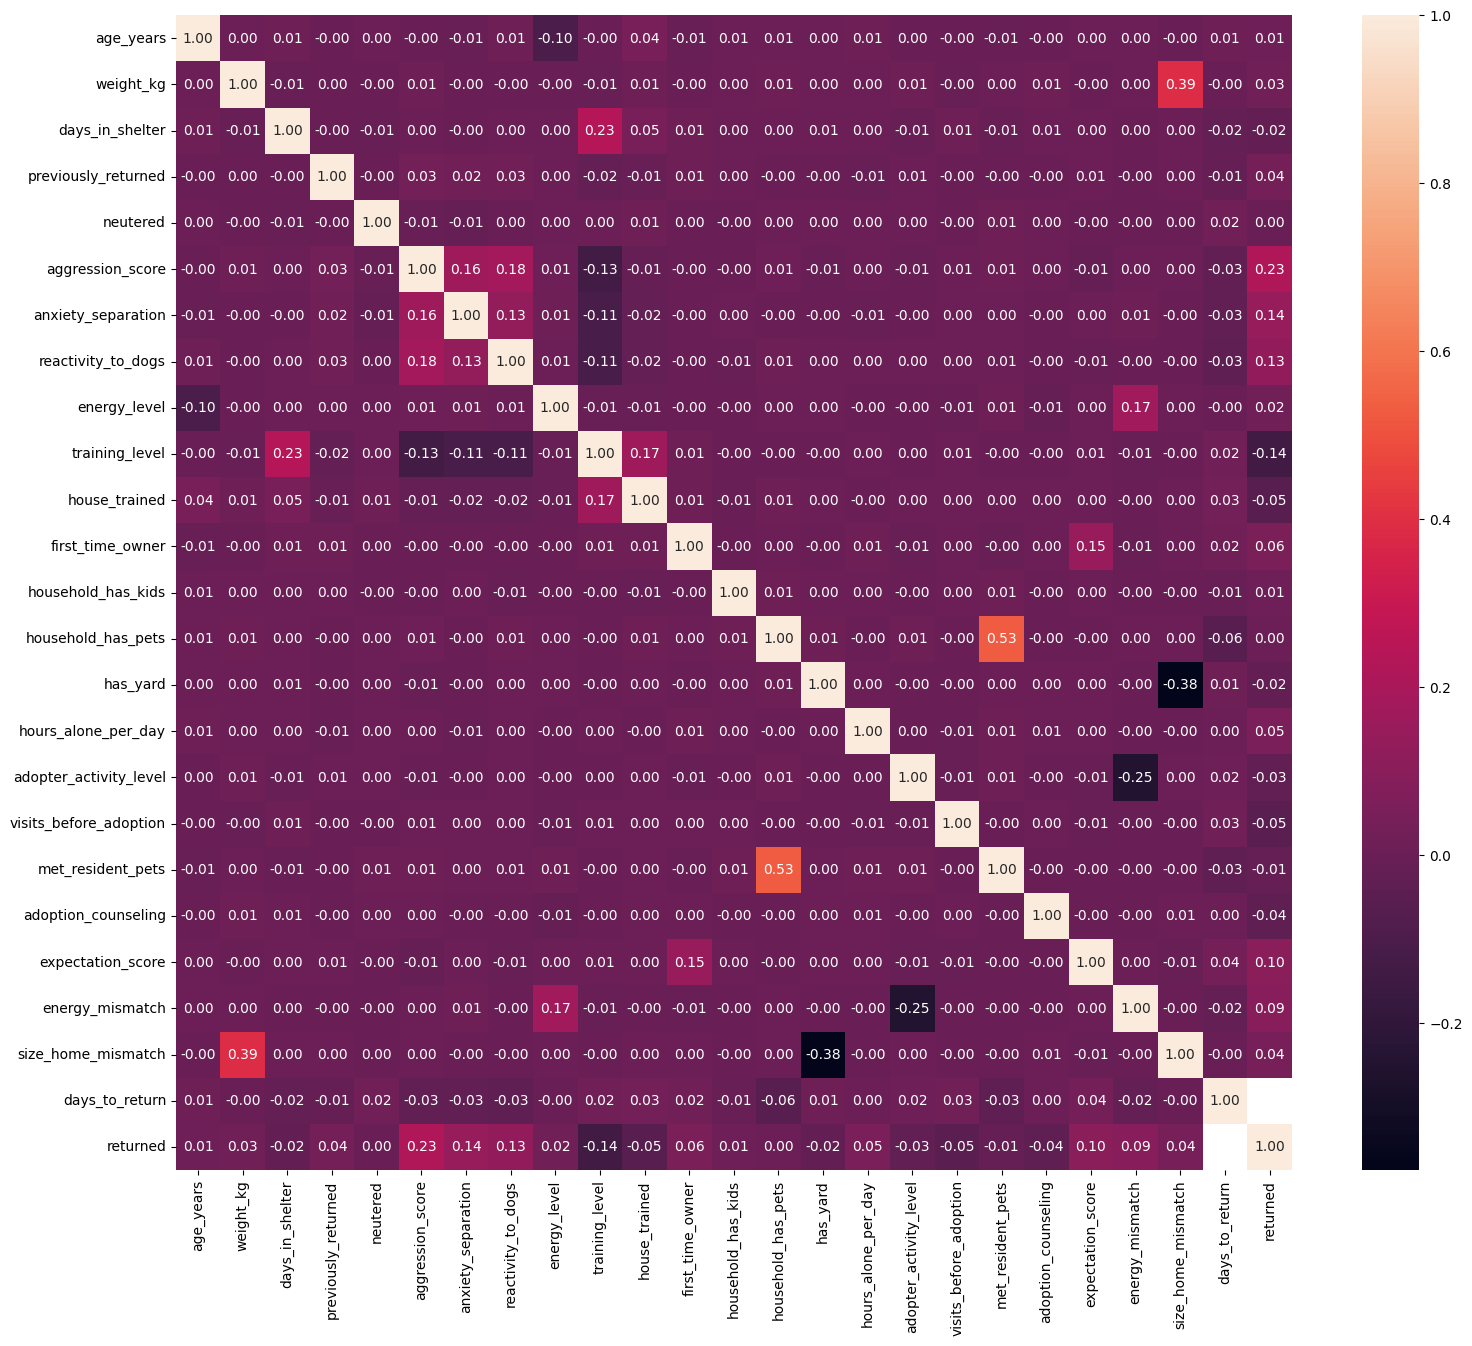

In [ ]:
plt.figure(figsize=(18,15))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f')
plt.show()

In [ ]:
df.drop(columns= ['adoption_id' , 'neutered'])

,age_years,size,weight_kg,breed_group,intake_type,days_in_shelter,previously_returned,medical_needs,aggression_score,anxiety_separation,...,adopter_activity_level,visits_before_adoption,met_resident_pets,adoption_counseling,expectation_score,energy_mismatch,size_home_mismatch,return_reason,days_to_return,returned
0,2.6,small,7.2,mixed,stray,51,0,none,1.5,8.8,...,2.6,1,0,0,7.3,1.4,0,kept,NaN,0
1,5.4,large,27.9,sporting,stray,38,1,none,4.8,5.2,...,3.8,1,0,0,6.2,4.2,0,kept,NaN,0
2,3.5,medium,15.4,mixed,owner_surrender,14,0,none,1.3,7.2,...,1.1,1,0,0,8.1,3.5,0,kept,NaN,0
3,7.3,medium,23.2,working,stray,9,0,none,0.0,3.5,...,7.8,3,0,1,10.0,0.8,0,unmet_expectations,4.5,1
4,0.7,medium,16.2,mixed,stray,35,1,minor,4.2,2.7,...,3.6,1,0,0,7.9,6.4,0,aggression,12.9,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41995,10.9,small,6.9,working,stray,18,0,none,5.1,2.3,...,6.9,1,0,1,5.4,4.2,0,kept,NaN,0
41996,5.3,small,5.9,toy,stray,42,0,none,4.2,4.4,...,7.1,3,0,1,5.9,0.6,0,kept,NaN,0
41997,1.8,large,30.9,herding,stray,42,0,none,5.8,6.1,...,4.7,1,0,0,5.3,5.3,0,kept,NaN,0
41998,1.7,small,6.9,mixed,stray,24,0,minor,3.1,4.0,...,0.3,1,0,0,1.9,7.1,0,kept,NaN,0


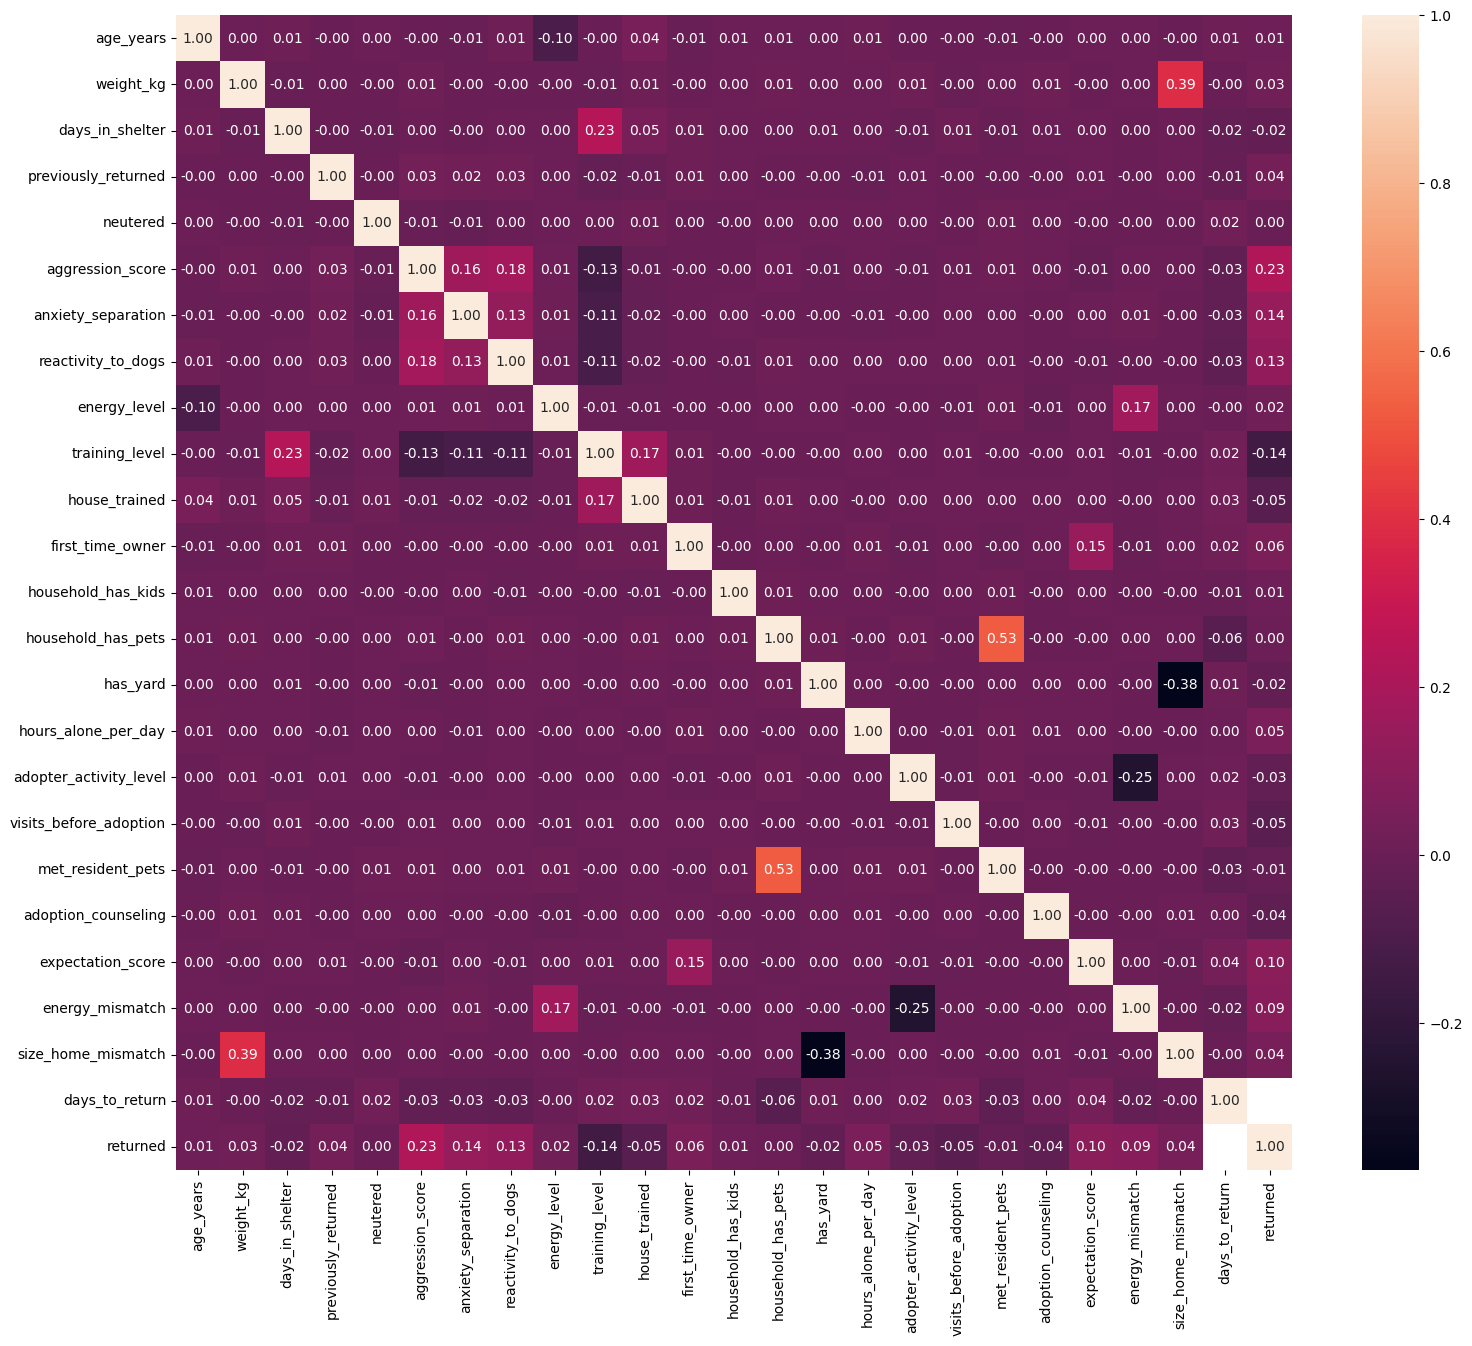

In [ ]:
plt.figure(figsize=(18,15))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f')
plt.show()

In [ ]:
def detect_outliers_iqr(df, features=None):

    """

    หา outlier ด้วยวิธี IQR ในแต่ละ feature

    คืนค่าเป็น dict บอกจำนวน/ index ของ outlier แต่ละ feature

    """

    if features is None:

        features = df.select_dtypes(include=[np.number]).columns.tolist()



    outlier_summary = {}



    for col in features:

        Q1 = df[col].quantile(0.25)

        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR

        upper_bound = Q3 + 1.5 * IQR



        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]



        outlier_summary[col] = {

            'count': len(outliers),

            'percentage': round(len(outliers) / len(df) * 100, 2),

            'lower_bound': lower_bound,

            'upper_bound': upper_bound,

            'outlier_index': outliers.index.tolist()

        }



    return outlier_summary


# ตัวอย่างการใช้งาน

# df = pd.read_csv('your_data.csv')

result = detect_outliers_iqr(df)


for col, info in result.items():

    print(f"Feature: {col}")

    print(f"  Outlier count: {info['count']} ({info['percentage']}%)")

    print(f"  Bounds: [{info['lower_bound']:.2f}, {info['upper_bound']:.2f}]")

    print("-" * 40)

Feature: age_years
  Outlier count: 1222 (2.91%)
  Bounds: [-3.30, 10.30]
----------------------------------------
Feature: size
  Outlier count: 0 (0.0%)
  Bounds: [-2.00, 6.00]
----------------------------------------
Feature: weight_kg
  Outlier count: 104 (0.25%)
  Bounds: [-20.80, 58.40]
----------------------------------------
Feature: days_in_shelter
  Outlier count: 1422 (3.39%)
  Bounds: [-33.50, 98.50]
----------------------------------------
Feature: previously_returned
  Outlier count: 4723 (11.25%)
  Bounds: [0.00, 0.00]
----------------------------------------
Feature: neutered
  Outlier count: 2999 (7.14%)
  Bounds: [1.00, 1.00]
----------------------------------------
Feature: aggression_score
  Outlier count: 142 (0.34%)
  Bounds: [-3.20, 8.00]
----------------------------------------
Feature: anxiety_separation
  Outlier count: 0 (0.0%)
  Bounds: [-2.00, 10.00]
----------------------------------------
Feature: reactivity_to_dogs
  Outlier count: 147 (0.35%)
  Bounds: 

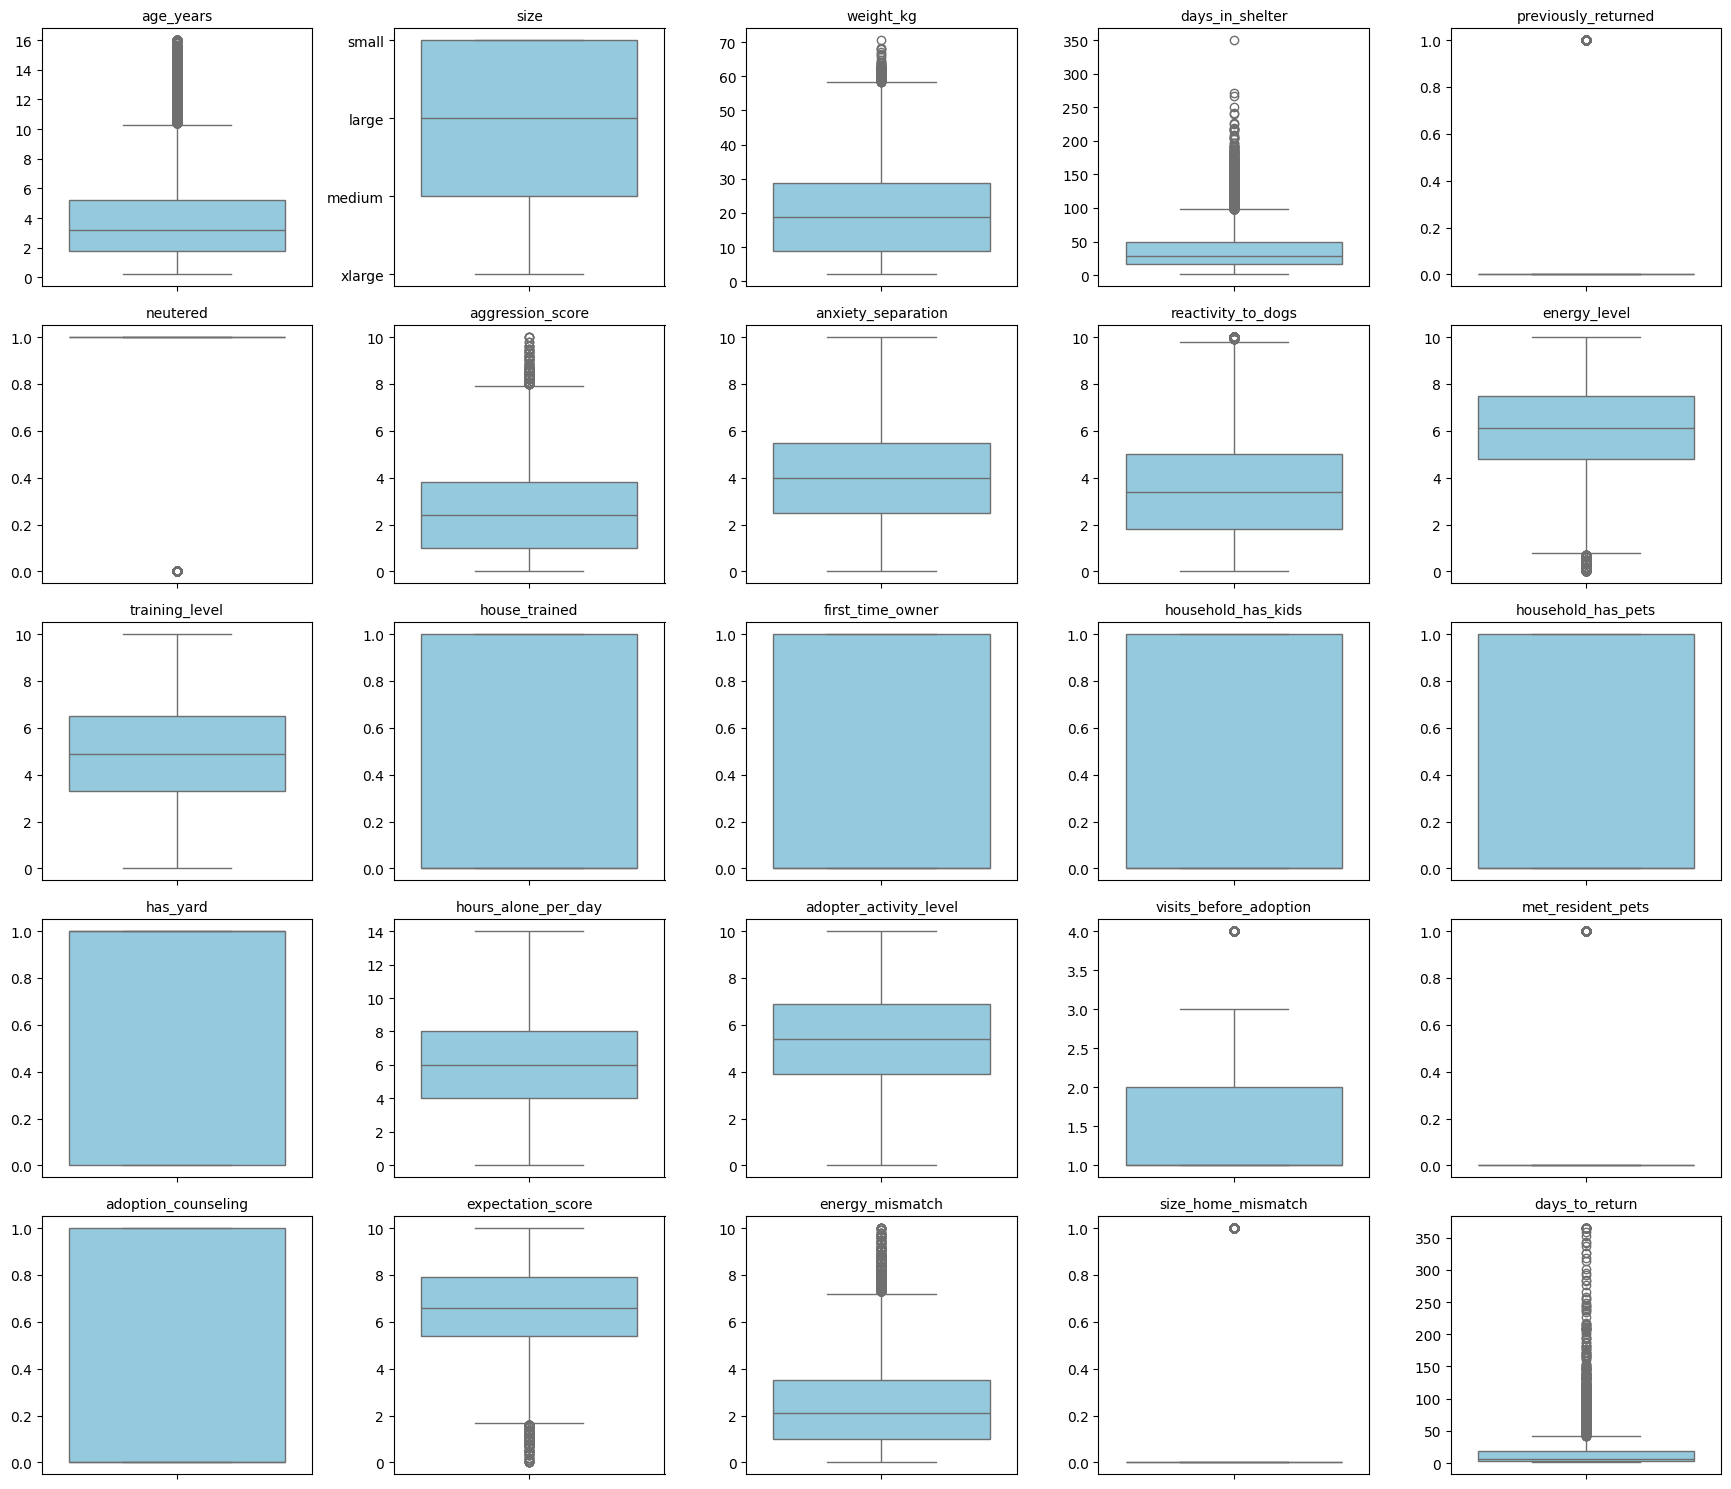

In [ ]:
def plot_all_boxplots(df, features, ncols=5):
    n = len(features)
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*3.5, nrows*3))
    axes = axes.flatten()

    for i, col in enumerate(features):
        sns.boxplot(y=df[col], ax=axes[i], color='skyblue')
        axes[i].set_title(col, fontsize=10)
        axes[i].set_xlabel('')
        axes[i].set_ylabel('')

    # ซ่อนช่องว่างที่เหลือ
    for j in range(i+1, len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.savefig('boxplots_all_features.png', dpi=150)
    plt.show()

plot_all_boxplots(df, features)

/tmp/ipykernel_4412/4062384110.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=outlier_report, x='outlier_pct', y='feature', palette='Reds_r')
/tmp/ipykernel_4412/4062384110.py:6: UserWarning: Glyph 3648 (\N{THAI CHARACTER SARA E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4412/4062384110.py:6: UserWarning: Glyph 3611 (\N{THAI CHARACTER PO PLA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4412/4062384110.py:6: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4412/4062384110.py:6: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4412/4062384110.py:6: UserWarning: Glyph 3660 (\N{THAI CHARACTER THANTHAKHAT}) missing from font(s) DejaVu 

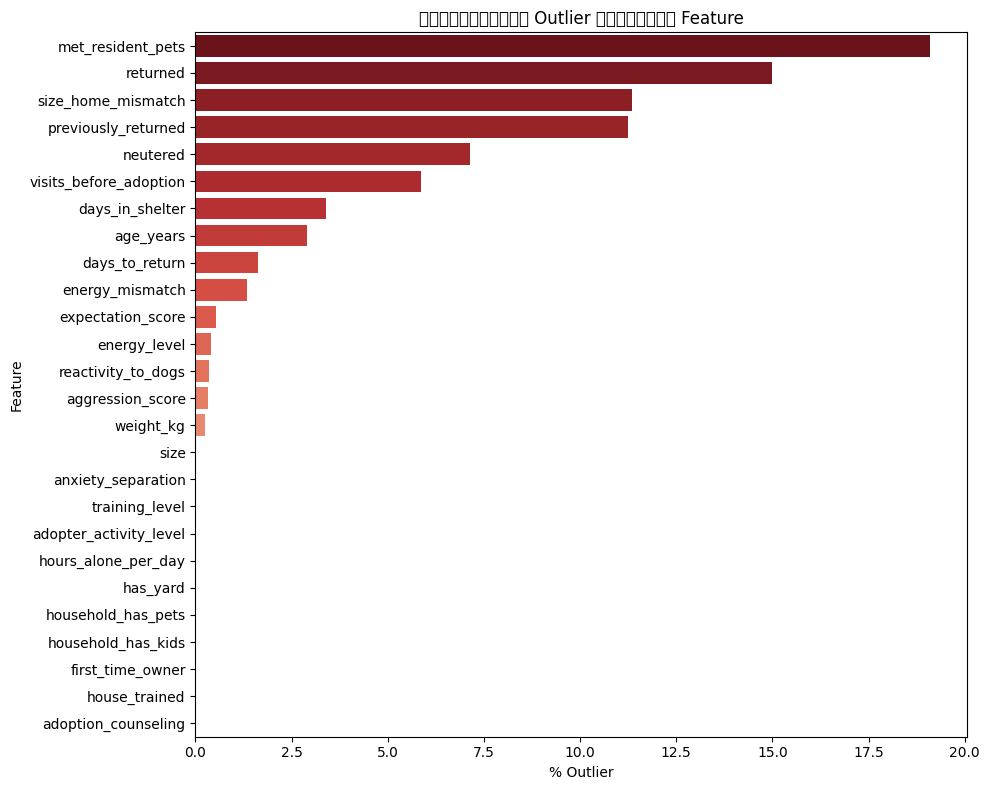

In [ ]:
plt.figure(figsize=(10, 8))
sns.barplot(data=outlier_report, x='outlier_pct', y='feature', palette='Reds_r')
plt.xlabel('% Outlier')
plt.ylabel('Feature')
plt.title('เปอร์เซ็นต์ Outlier ของแต่ละ Feature')
plt.tight_layout()
plt.savefig('outlier_percentage_summary.png', dpi=150)
plt.show()


# **Visualization**

Overall Adoption Success Rate: 85.0%


/tmp/ipykernel_4412/2298434438.py:61: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = df.groupby(bins)['success'].mean() * 100
/tmp/ipykernel_4412/2298434438.py:61: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = df.groupby(bins)['success'].mean() * 100
/tmp/ipykernel_4412/2298434438.py:61: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = df.groupby(bins)['success'].mean() * 100
/tmp/ipykernel_4412/22984

               feature    impact
      aggression_score 20.251676
    anxiety_separation 13.464528
        training_level 12.822355
    reactivity_to_dogs 11.539310
     expectation_score  9.208931
       energy_mismatch  8.162099
visits_before_adoption  5.700233
    size_home_mismatch  4.882982
   hours_alone_per_day  4.422928
adopter_activity_level  4.249094
   previously_returned  4.243610
      first_time_owner  4.116454
         house_trained  3.864079
          energy_level  3.074331
                  size  2.933567
             age_years  2.838011
   adoption_counseling  2.689241
             weight_kg  2.502843
              has_yard  1.740375
       days_in_shelter  1.739121
     met_resident_pets  1.125042
    household_has_kids  0.894720
              neutered  0.094647
    household_has_pets  0.084156
        days_to_return  0.000000


/tmp/ipykernel_4412/2298434438.py:79: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = (df.groupby(bins)['success'].mean() * 100)


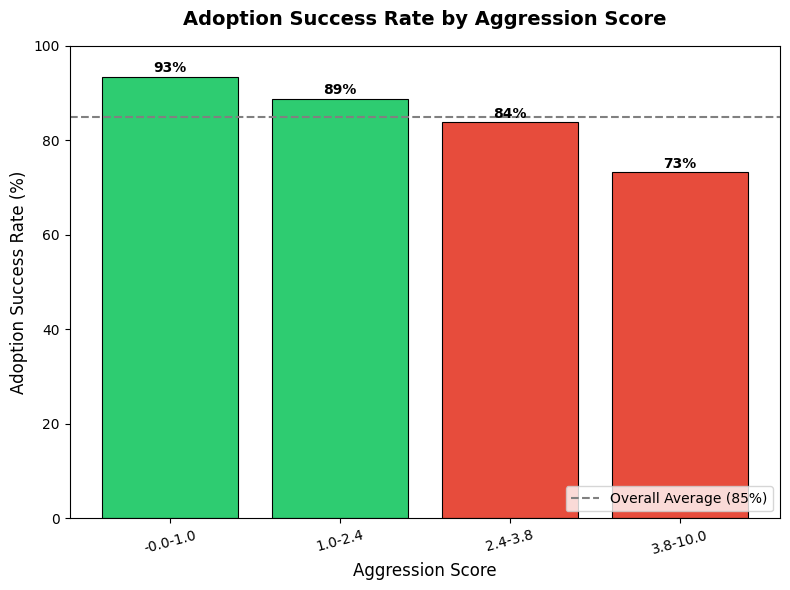

✔ Saved: success_rate_plots/01_success_rate_by_aggression_score.png


/tmp/ipykernel_4412/2298434438.py:79: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = (df.groupby(bins)['success'].mean() * 100)


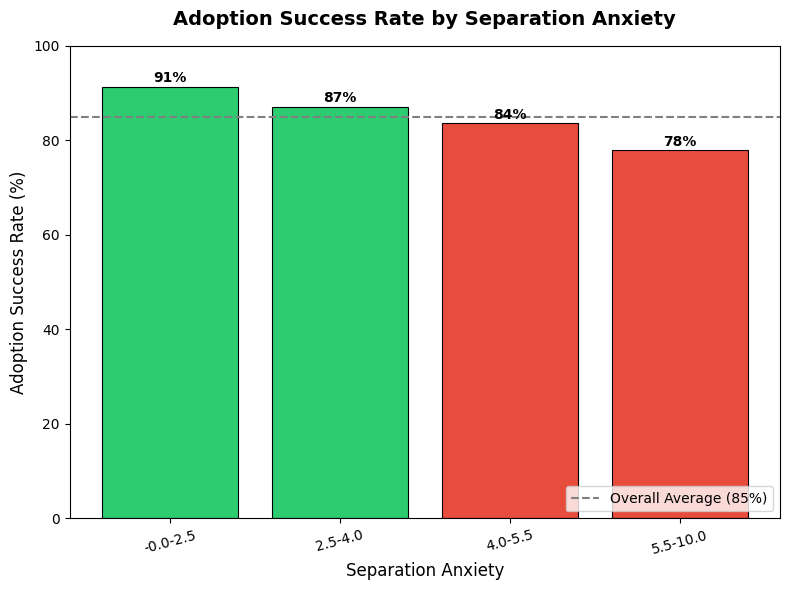

✔ Saved: success_rate_plots/02_success_rate_by_anxiety_separation.png


/tmp/ipykernel_4412/2298434438.py:79: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = (df.groupby(bins)['success'].mean() * 100)


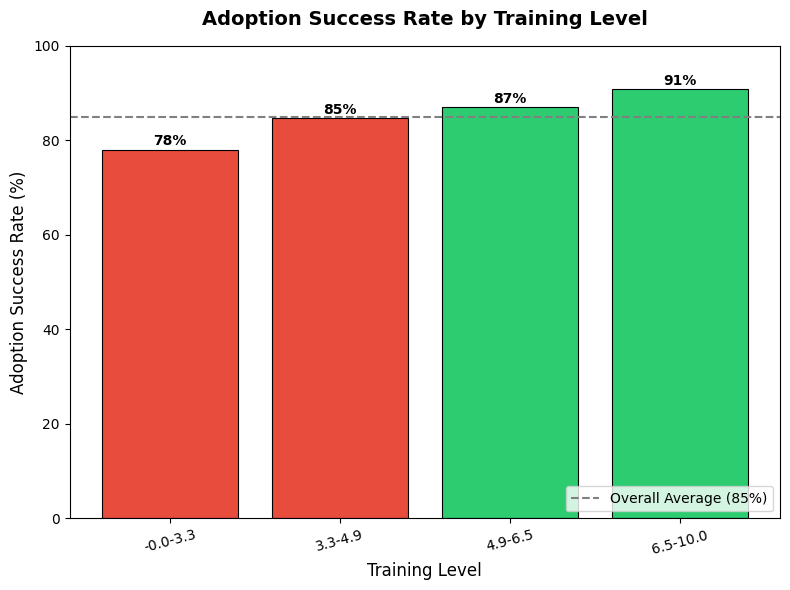

✔ Saved: success_rate_plots/03_success_rate_by_training_level.png


/tmp/ipykernel_4412/2298434438.py:79: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = (df.groupby(bins)['success'].mean() * 100)


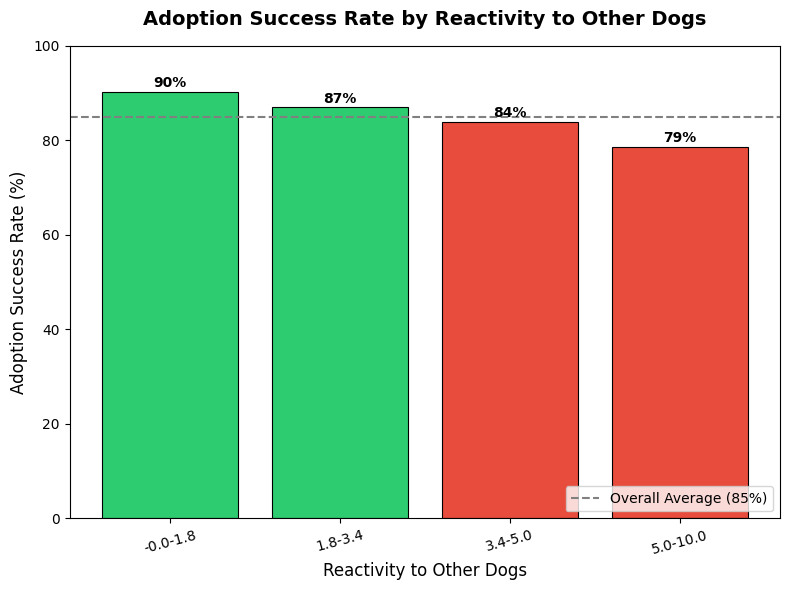

✔ Saved: success_rate_plots/04_success_rate_by_reactivity_to_dogs.png


/tmp/ipykernel_4412/2298434438.py:79: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = (df.groupby(bins)['success'].mean() * 100)


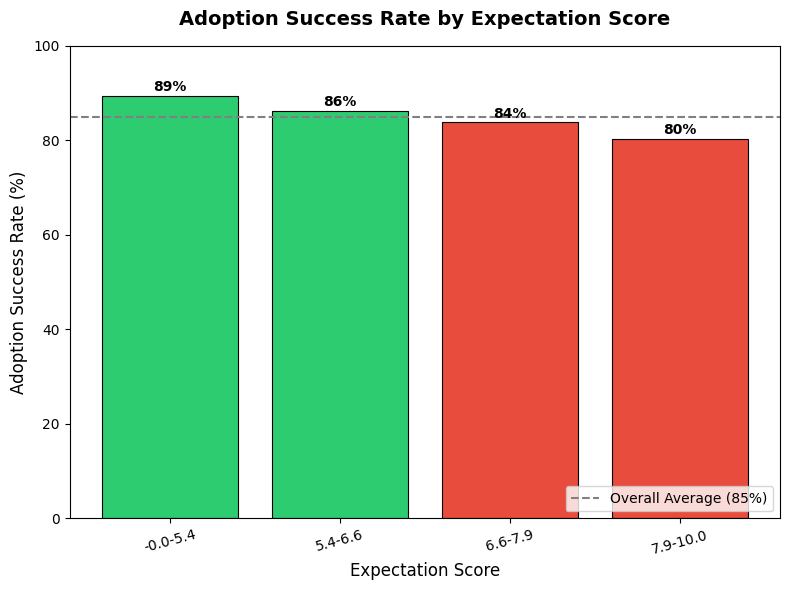

✔ Saved: success_rate_plots/05_success_rate_by_expectation_score.png


/tmp/ipykernel_4412/2298434438.py:79: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = (df.groupby(bins)['success'].mean() * 100)


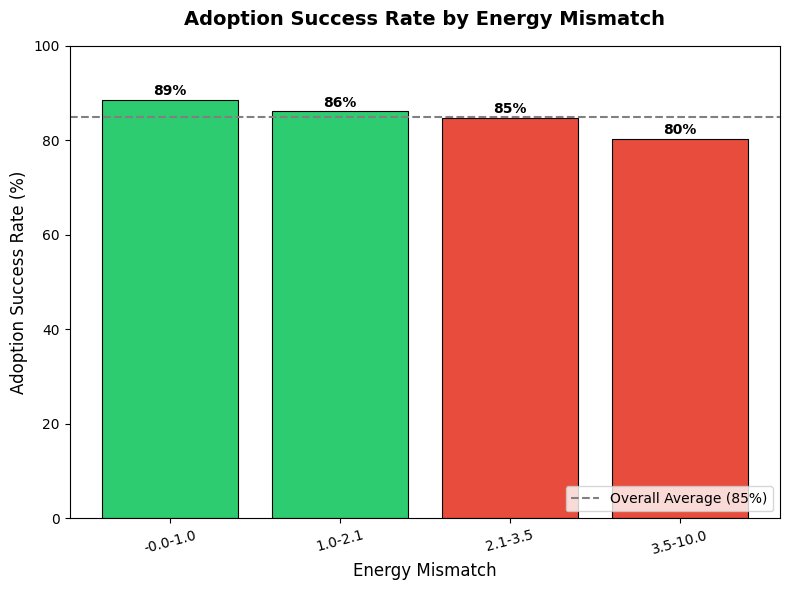

✔ Saved: success_rate_plots/06_success_rate_by_energy_mismatch.png


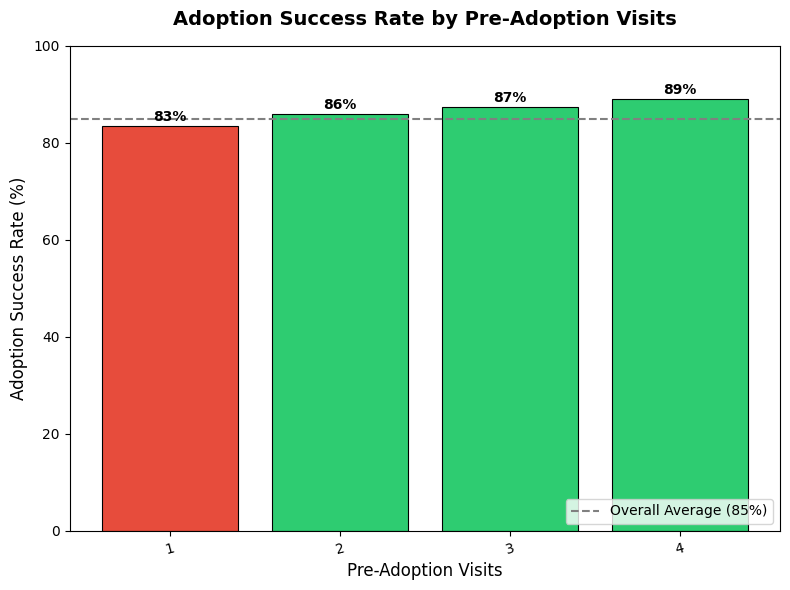

✔ Saved: success_rate_plots/07_success_rate_by_visits_before_adoption.png


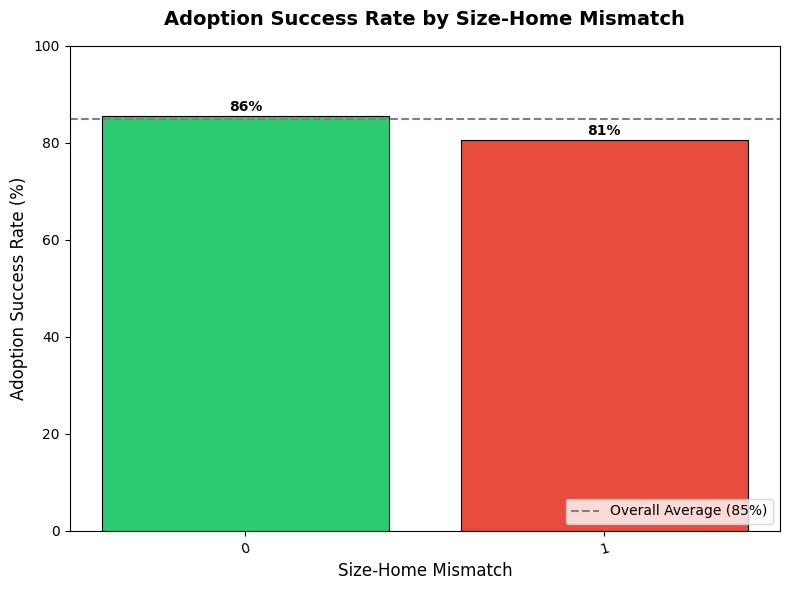

✔ Saved: success_rate_plots/08_success_rate_by_size_home_mismatch.png


/tmp/ipykernel_4412/2298434438.py:79: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = (df.groupby(bins)['success'].mean() * 100)


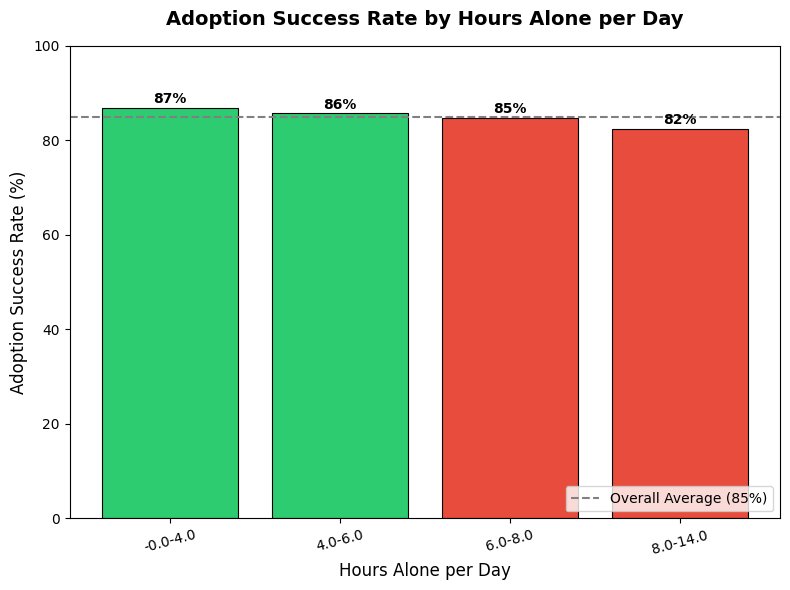

✔ Saved: success_rate_plots/09_success_rate_by_hours_alone_per_day.png


/tmp/ipykernel_4412/2298434438.py:79: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = (df.groupby(bins)['success'].mean() * 100)


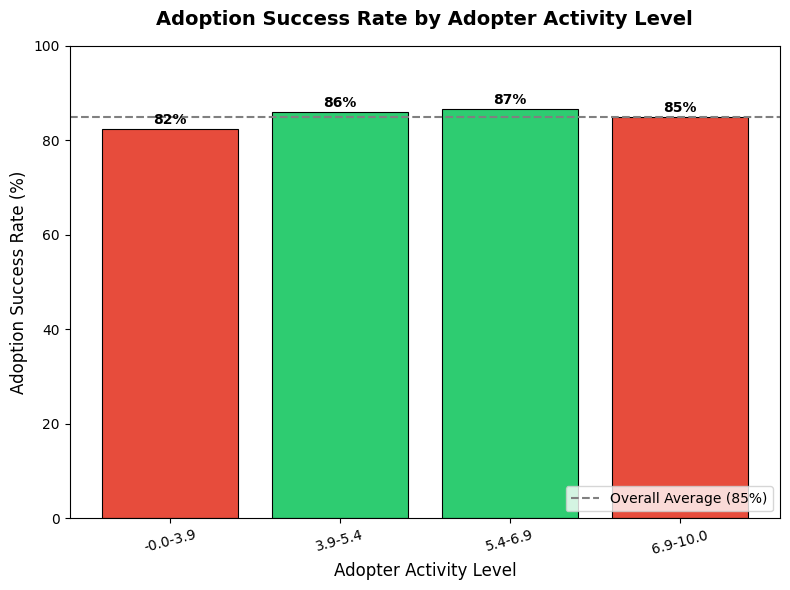

✔ Saved: success_rate_plots/10_success_rate_by_adopter_activity_level.png


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

output_dir = 'success_rate_plots'
os.makedirs(output_dir, exist_ok=True)

# ---------- 1. สร้างคอลัมน์ success (ตรงข้ามกับ returned) ----------
df['success'] = 1 - df['returned']
overall_success_rate = df['success'].mean() * 100
print(f"Overall Adoption Success Rate: {overall_success_rate:.1f}%")

# ---------- 2. Label map ภาษาอังกฤษ ----------
label_map = {
    'age_years': 'Age (years)',
    'size': 'Size',
    'weight_kg': 'Weight (kg)',
    'days_in_shelter': 'Days in Shelter',
    'previously_returned': 'Previously Returned',
    'neutered': 'Neutered',
    'aggression_score': 'Aggression Score',
    'anxiety_separation': 'Separation Anxiety',
    'reactivity_to_dogs': 'Reactivity to Other Dogs',
    'energy_level': 'Energy Level',
    'training_level': 'Training Level',
    'house_trained': 'House Trained',
    'first_time_owner': 'First-Time Owner',
    'household_has_kids': 'Household Has Kids',
    'household_has_pets': 'Household Has Other Pets',
    'has_yard': 'Has Yard',
    'hours_alone_per_day': 'Hours Alone per Day',
    'adopter_activity_level': 'Adopter Activity Level',
    'visits_before_adoption': 'Pre-Adoption Visits',
    'met_resident_pets': 'Met Resident Pets Before',
    'adoption_counseling': 'Received Adoption Counseling',
    'expectation_score': 'Expectation Score',
    'energy_mismatch': 'Energy Mismatch',
    'size_home_mismatch': 'Size-Home Mismatch',
}

def get_label(col):
    return label_map.get(col, col.replace('_', ' ').title())

def is_discrete(series, max_unique=6):
    return series.nunique() <= max_unique

# ---------- 3. หาฟีเจอร์ที่มีผลต่อ success rate มากที่สุด ----------
features = [c for c in df.select_dtypes(include=[np.number]).columns
            if c not in ['returned', 'success']]

impact_scores = []
for col in features:
    if is_discrete(df[col]):
        rates = df.groupby(col)['success'].mean() * 100
        impact = rates.max() - rates.min()
    else:
        # แบ่งเป็น bin 4 กลุ่ม (quartile)
        bins = pd.qcut(df[col], 4, duplicates='drop')
        rates = df.groupby(bins)['success'].mean() * 100
        impact = rates.max() - rates.min()
    impact_scores.append((col, impact))

impact_df = pd.DataFrame(impact_scores, columns=['feature', 'impact']).sort_values('impact', ascending=False)
print(impact_df.to_string(index=False))

# ---------- 4. วาดกราฟ Success Rate แยกทีละ feature ----------
top_n = 10  # เลือกเฉพาะ 10 ฟีเจอร์ที่มีผลมากที่สุด
for i, row in impact_df.head(top_n).iterrows():
    col = row['feature']
    fig, ax = plt.subplots(figsize=(8, 6))

    if is_discrete(df[col]):
        rates = (df.groupby(col)['success'].mean() * 100).sort_index()
        x_labels = [str(x) for x in rates.index]
    else:
        bins = pd.qcut(df[col], 4, duplicates='drop')
        rates = (df.groupby(bins)['success'].mean() * 100)
        x_labels = [f"{b.left:.1f}-{b.right:.1f}" for b in rates.index]

    colors = ['#2ecc71' if v >= overall_success_rate else '#e74c3c' for v in rates.values]
    bars = ax.bar(x_labels, rates.values, color=colors, edgecolor='black', linewidth=0.8)

    # เส้น benchmark ค่าเฉลี่ยรวม
    ax.axhline(overall_success_rate, color='gray', linestyle='--', linewidth=1.5,
               label=f'Overall Average ({overall_success_rate:.0f}%)')

    # ใส่ตัวเลข % บนแท่งกราฟ
    for bar, v in zip(bars, rates.values):
        ax.text(bar.get_x() + bar.get_width()/2, v + 1, f'{v:.0f}%',
                ha='center', fontsize=10, fontweight='bold')

    ax.set_ylim(0, 100)
    ax.set_ylabel('Adoption Success Rate (%)', fontsize=12)
    ax.set_xlabel(get_label(col), fontsize=12)
    ax.set_title(f'Adoption Success Rate by {get_label(col)}', fontsize=14, fontweight='bold', pad=15)
    ax.legend(loc='lower right')
    plt.xticks(rotation=15)
    plt.tight_layout()

    rank = impact_df.index.get_loc(i) + 1
    filename = f"{output_dir}/{rank:02d}_success_rate_by_{col}.png"
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    print(f"✔ Saved: {filename}")

In [ ]:
# ============================================================
# Dog Adoption Success — Does the Match Last?
# Exploratory Data Visualization for Presentation
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["axes.titleweight"] = "bold"

PALETTE = {"kept": "#2E86AB", "returned": "#E4572E"}
SEQ = "RdYlBu_r"

df = pd.read_csv("dog_adoption_master.csv")
df["outcome"] = np.where(df["returned"] == 1, "Returned", "Stayed Home")

def show(fig, name):
    fig.savefig(f"{name}.png")
    plt.show()

def rate_by(col, min_n=30):
    """Return-rate table by a categorical column."""
    g = (df.groupby(col)["returned"]
           .agg(return_rate=lambda s: s.mean() * 100, n="size")
           .query("n >= @min_n")
           .sort_values("return_rate"))
    return g

BASE = df["returned"].mean() * 100   # 15.3%

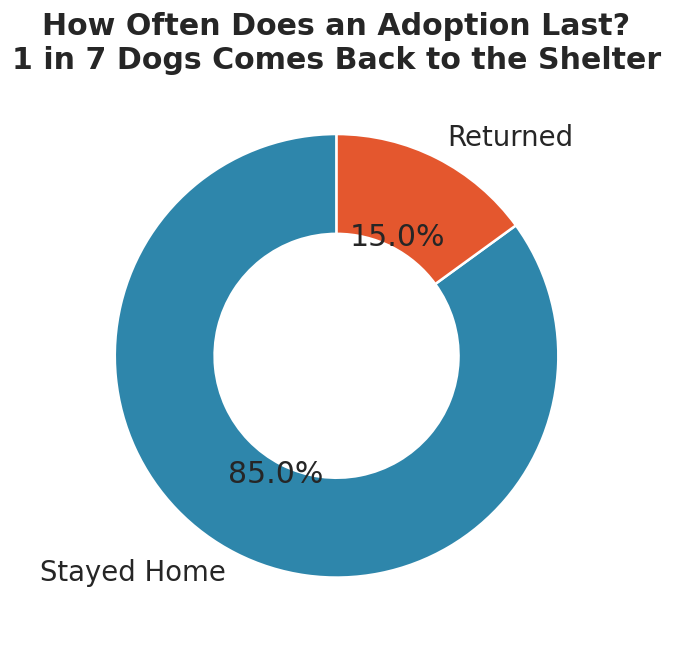

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
counts = df["outcome"].value_counts()
ax.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
       colors=[PALETTE["kept"], PALETTE["returned"]],
       wedgeprops=dict(width=0.45, edgecolor="white"))
ax.set_title("How Often Does an Adoption Last?\n1 in 7 Dogs Comes Back to the Shelter")
show(fig, "01_overall_outcome")


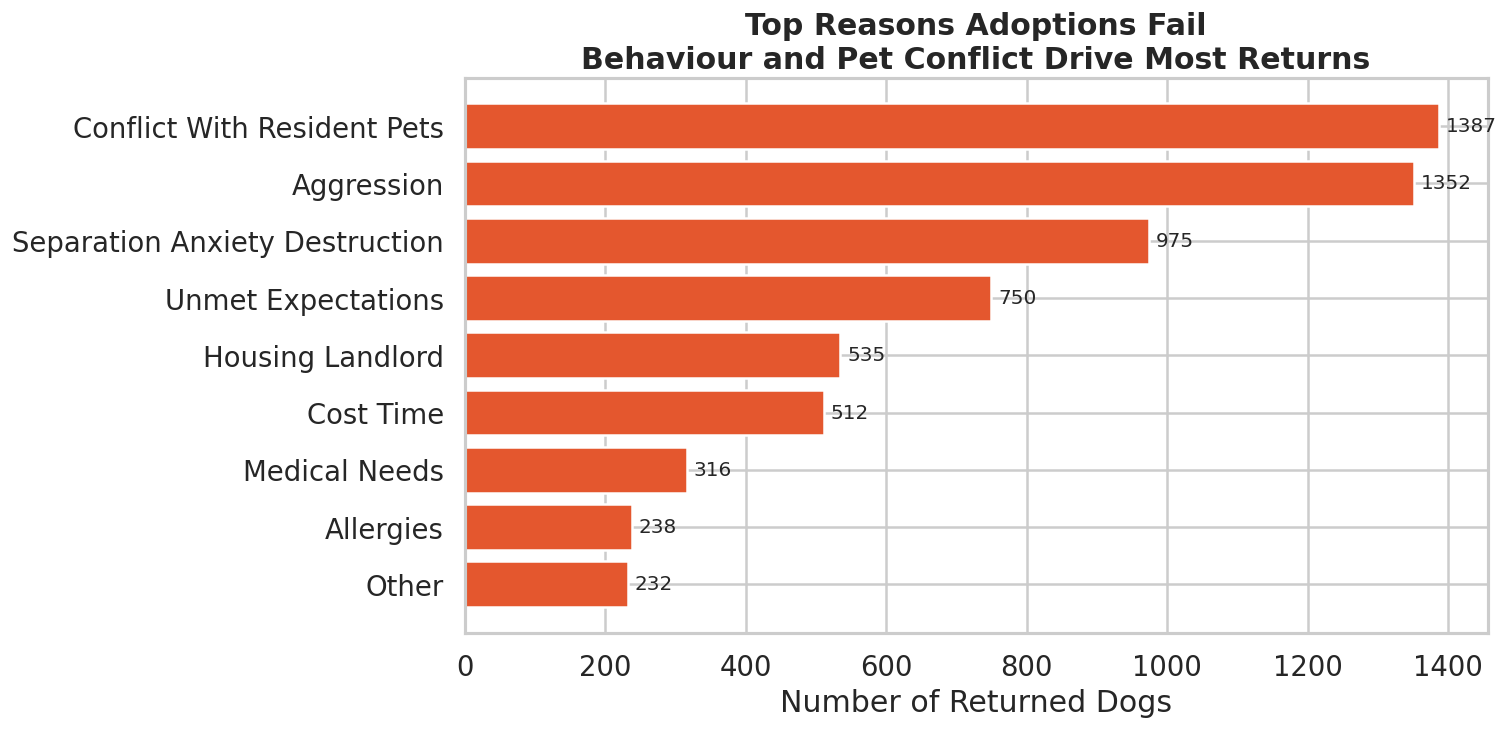

In [ ]:
fig, ax = plt.subplots(figsize=(11, 6))
reasons = (df.loc[df["returned"] == 1, "return_reason"]
             .value_counts().sort_values())
reasons.index = reasons.index.str.replace("_", " ").str.title()
bars = ax.barh(reasons.index, reasons.values, color=PALETTE["returned"])
ax.bar_label(bars, padding=4, fontsize=12)
ax.set_xlabel("Number of Returned Dogs")
ax.set_title("Top Reasons Adoptions Fail\nBehaviour and Pet Conflict Drive Most Returns")
show(fig, "02_return_reasons")

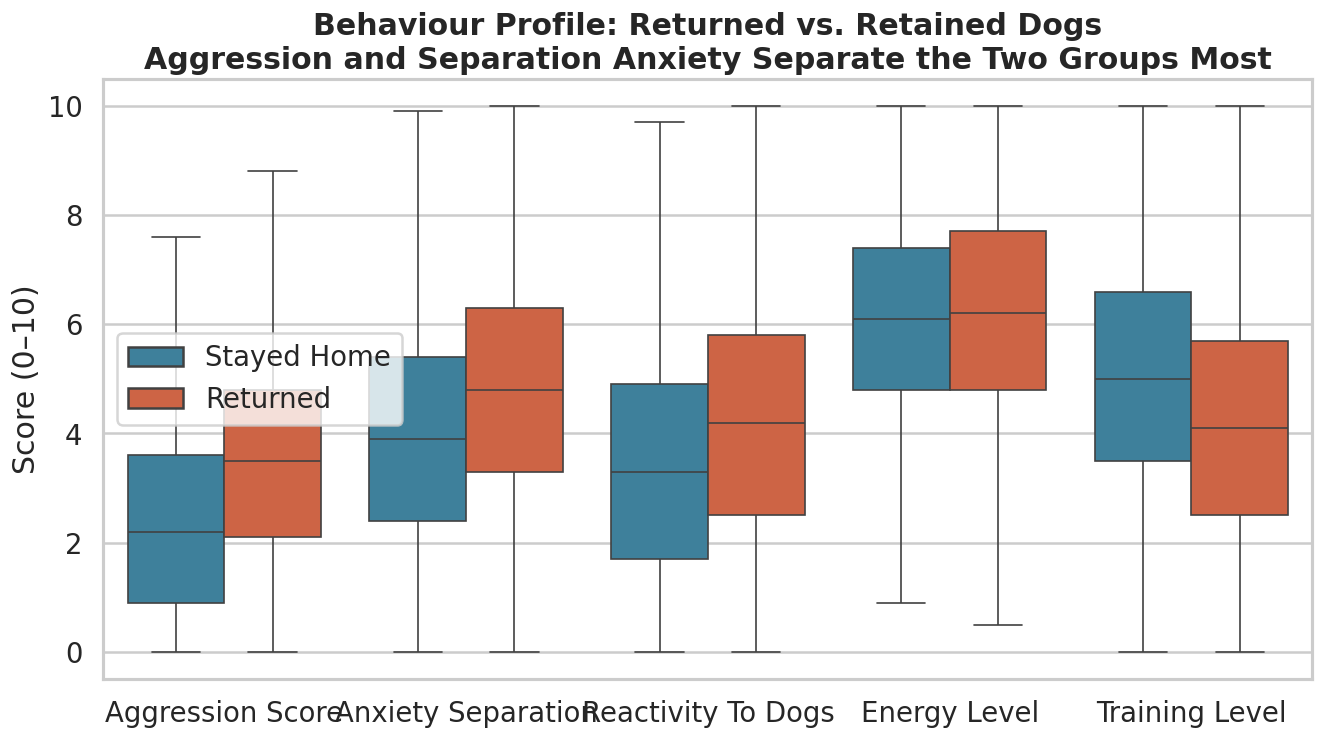

In [ ]:
behaviour = ["aggression_score", "anxiety_separation", "reactivity_to_dogs",
             "energy_level", "training_level"]
long = df.melt(id_vars="outcome", value_vars=behaviour,
               var_name="trait", value_name="score")
long["trait"] = long["trait"].str.replace("_", " ").str.title()

fig, ax = plt.subplots(figsize=(13, 6.5))
sns.boxplot(data=long, x="trait", y="score", hue="outcome",
            palette=[PALETTE["kept"], PALETTE["returned"]], ax=ax, fliersize=0)
ax.set_xlabel(""); ax.set_ylabel("Score (0–10)")
ax.set_title("Behaviour Profile: Returned vs. Retained Dogs\n"
             "Aggression and Separation Anxiety Separate the Two Groups Most")
ax.legend(title="")
show(fig, "03_behaviour_profile")

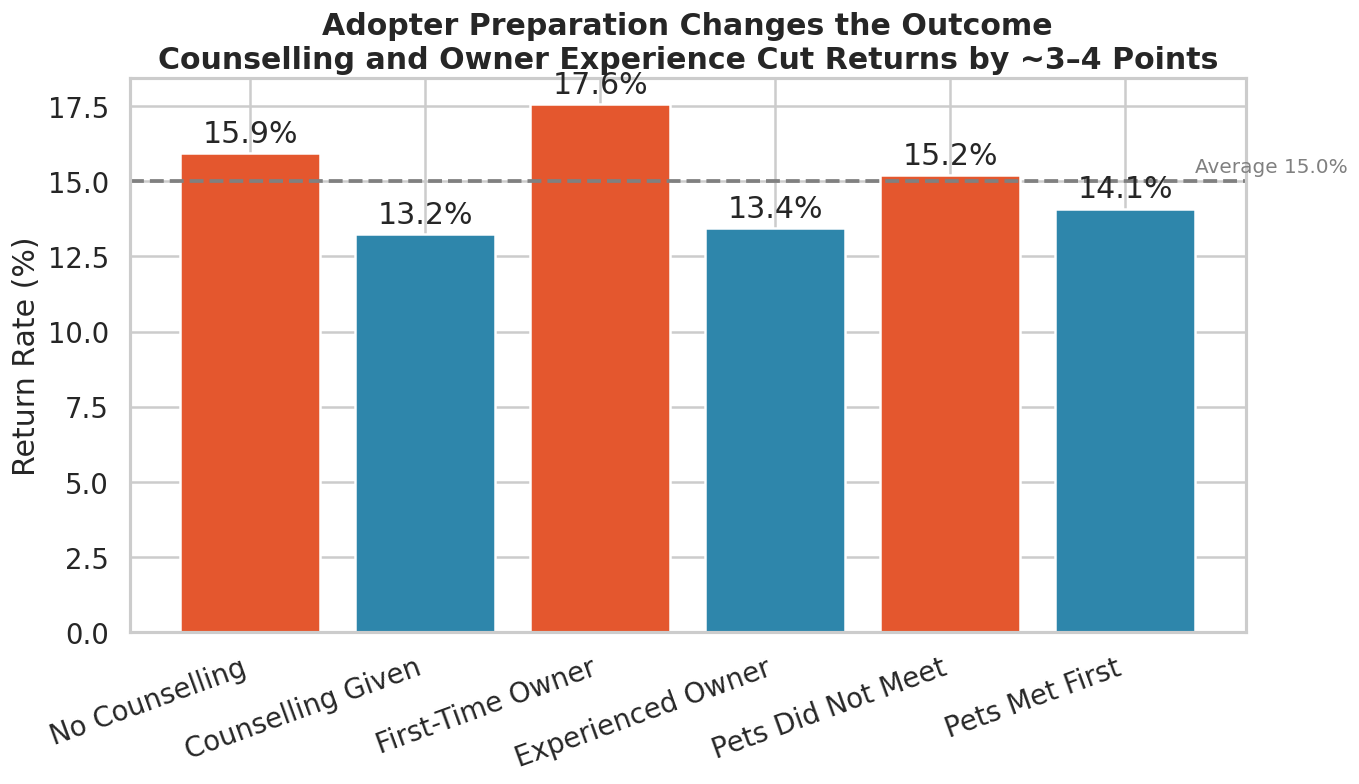

In [ ]:
prep = pd.DataFrame({
    "Factor": ["No Counselling", "Counselling Given",
               "First-Time Owner", "Experienced Owner",
               "Pets Did Not Meet", "Pets Met First"],
    "Return Rate": [
        df.loc[df.adoption_counseling == 0, "returned"].mean() * 100,
        df.loc[df.adoption_counseling == 1, "returned"].mean() * 100,
        df.loc[df.first_time_owner == 1, "returned"].mean() * 100,
        df.loc[df.first_time_owner == 0, "returned"].mean() * 100,
        df.loc[df.met_resident_pets == 0, "returned"].mean() * 100,
        df.loc[df.met_resident_pets == 1, "returned"].mean() * 100],
    "Group": ["Counselling"] * 2 + ["Experience"] * 2 + ["Meet & Greet"] * 2})

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(prep["Factor"], prep["Return Rate"],
              color=["#E4572E", "#2E86AB"] * 3)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.axhline(BASE, ls="--", c="grey")
ax.text(5.4, BASE + 0.3, f"Average {BASE:.1f}%", color="grey", fontsize=12)
ax.set_ylabel("Return Rate (%)"); plt.xticks(rotation=20, ha="right")
ax.set_title("Adopter Preparation Changes the Outcome\n"
             "Counselling and Owner Experience Cut Returns by ~3–4 Points")
show(fig, "04_adopter_preparation")

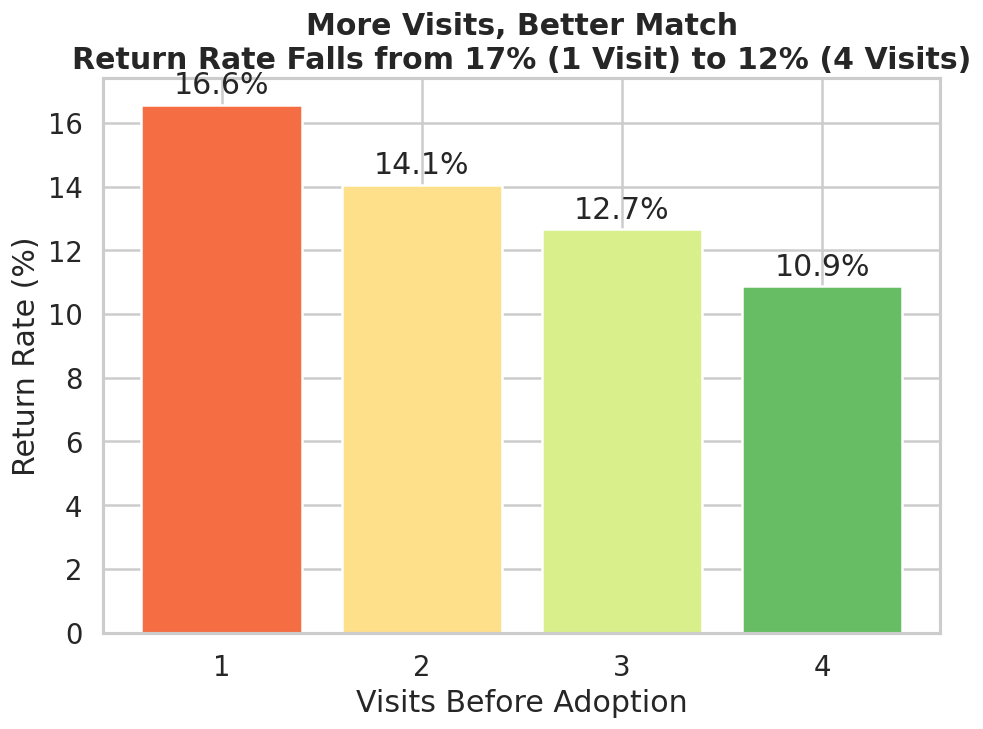

In [ ]:
v = rate_by("visits_before_adoption")
v = v.sort_index(ascending=True) # Sort by the number of visits in ascending order
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.bar(v.index.astype(str), v["return_rate"],
              color=sns.color_palette("RdYlGn", len(v)))
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlabel("Visits Before Adoption"); ax.set_ylabel("Return Rate (%)")
ax.set_title("More Visits, Better Match\n"
             "Return Rate Falls from 17% (1 Visit) to 12% (4 Visits)")
show(fig, "05_visits_before_adoption")

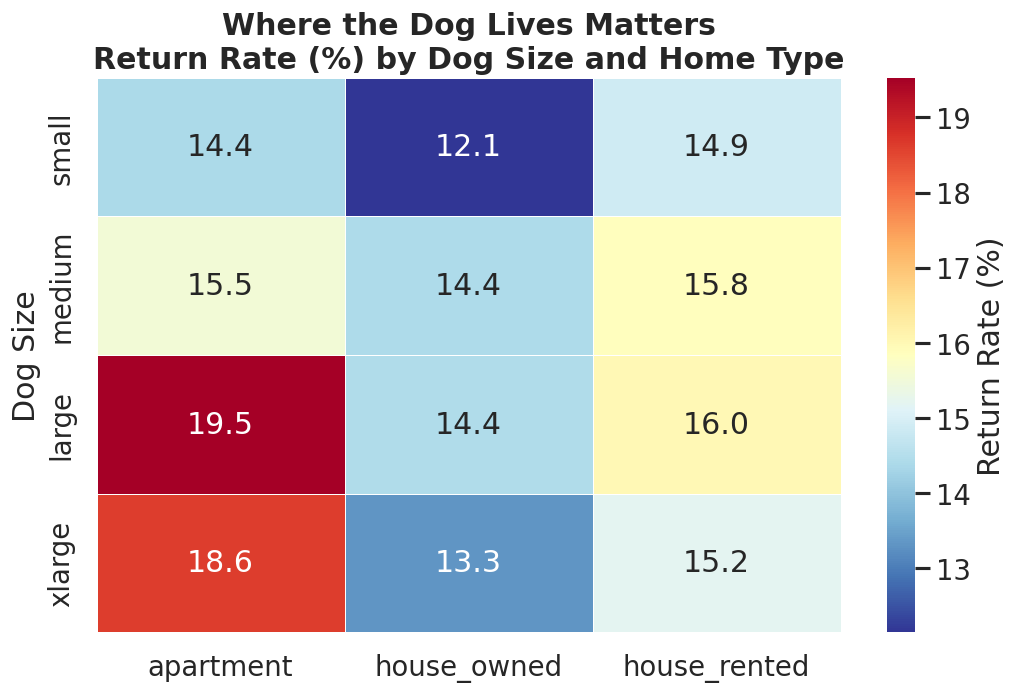

In [ ]:
pivot = (df.pivot_table(index="size", columns="home_type",
                        values="returned", aggfunc="mean") * 100)
pivot = pivot.reindex(["small", "medium", "large", "xlarge"])

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap=SEQ, ax=ax,
            cbar_kws={"label": "Return Rate (%)"}, linewidths=.5)
ax.set_xlabel(""); ax.set_ylabel("Dog Size")
ax.set_title("Where the Dog Lives Matters\n"
             "Return Rate (%) by Dog Size and Home Type")
show(fig, "06_size_vs_home")

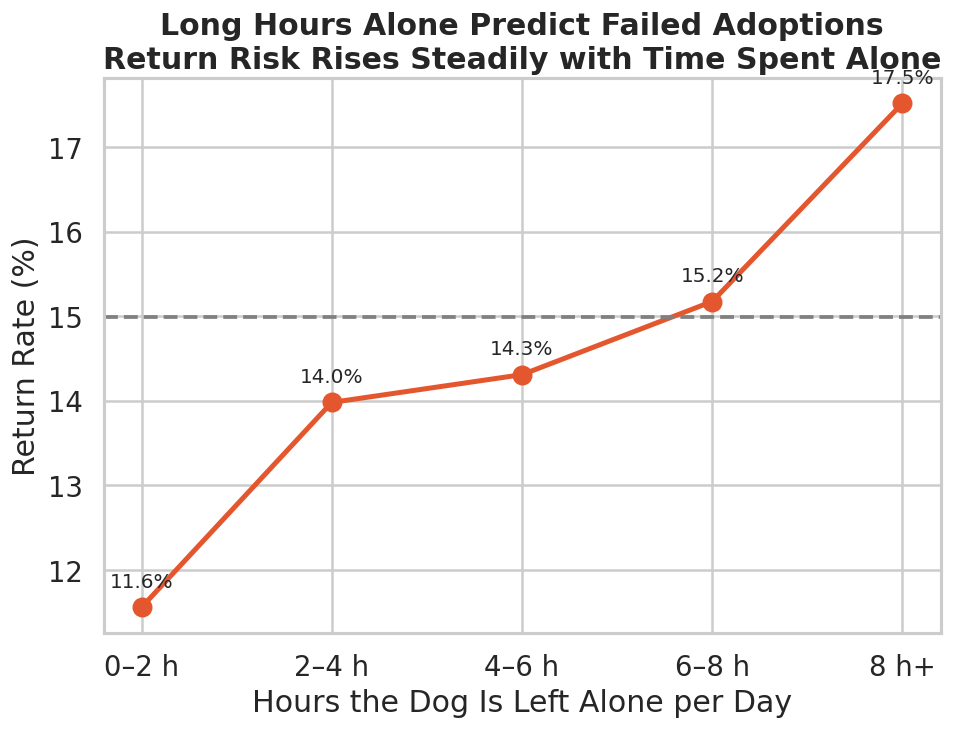

In [ ]:
df["alone_bin"] = pd.cut(df["hours_alone_per_day"], [-.1, 2, 4, 6, 8, 24],
                         labels=["0–2 h", "2–4 h", "4–6 h", "6–8 h", "8 h+"])
a = df.groupby("alone_bin", observed=True)["returned"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(a.index.astype(str), a.values, marker="o", lw=3,
        ms=11, color=PALETTE["returned"])
for x, y in zip(a.index.astype(str), a.values):
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points",
                xytext=(0, 12), ha="center", fontsize=12)
ax.axhline(BASE, ls="--", c="grey")
ax.set_xlabel("Hours the Dog Is Left Alone per Day")
ax.set_ylabel("Return Rate (%)")
ax.set_title("Long Hours Alone Predict Failed Adoptions\n"
             "Return Risk Rises Steadily with Time Spent Alone")
show(fig, "07_hours_alone")

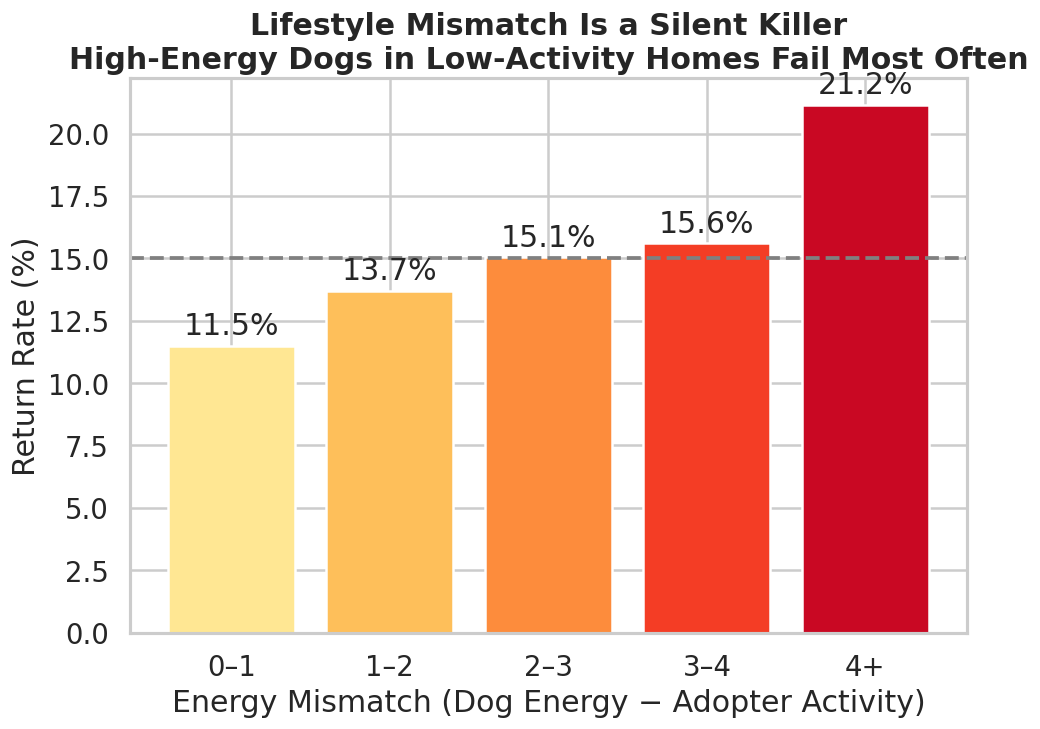

In [ ]:
df["mismatch_bin"] = pd.cut(df["energy_mismatch"], [-.1, 1, 2, 3, 4, 10],
                            labels=["0–1", "1–2", "2–3", "3–4", "4+"])
m = df.groupby("mismatch_bin", observed=True)["returned"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.bar(m.index.astype(str), m.values,
              color=sns.color_palette("YlOrRd", len(m)))
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.axhline(BASE, ls="--", c="grey")
ax.set_xlabel("Energy Mismatch (Dog Energy − Adopter Activity)")
ax.set_ylabel("Return Rate (%)")
ax.set_title("Lifestyle Mismatch Is a Silent Killer\n"
             "High-Energy Dogs in Low-Activity Homes Fail Most Often")
show(fig, "08_energy_mismatch")

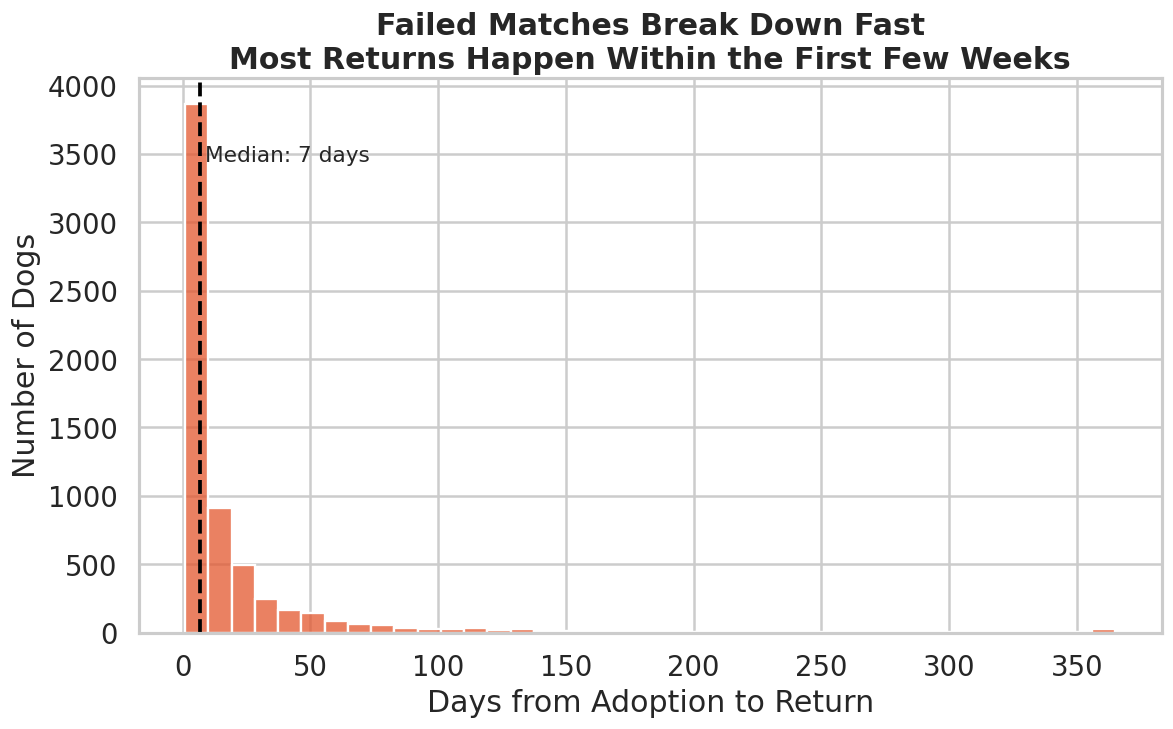

In [ ]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.histplot(df.loc[df.returned == 1, "days_to_return"], bins=40,
             color=PALETTE["returned"], ax=ax, edgecolor="white")
med = df["days_to_return"].median()
ax.axvline(med, ls="--", c="black")
ax.text(med + 2, ax.get_ylim()[1] * .85, f"Median: {med:.0f} days", fontsize=13)
ax.set_xlabel("Days from Adoption to Return"); ax.set_ylabel("Number of Dogs")
ax.set_title("Failed Matches Break Down Fast\n"
             "Most Returns Happen Within the First Few Weeks")
show(fig, "10_days_to_return")

/tmp/ipykernel_4412/2247676058.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, y="return_reason", x="days_to_return", order=order,


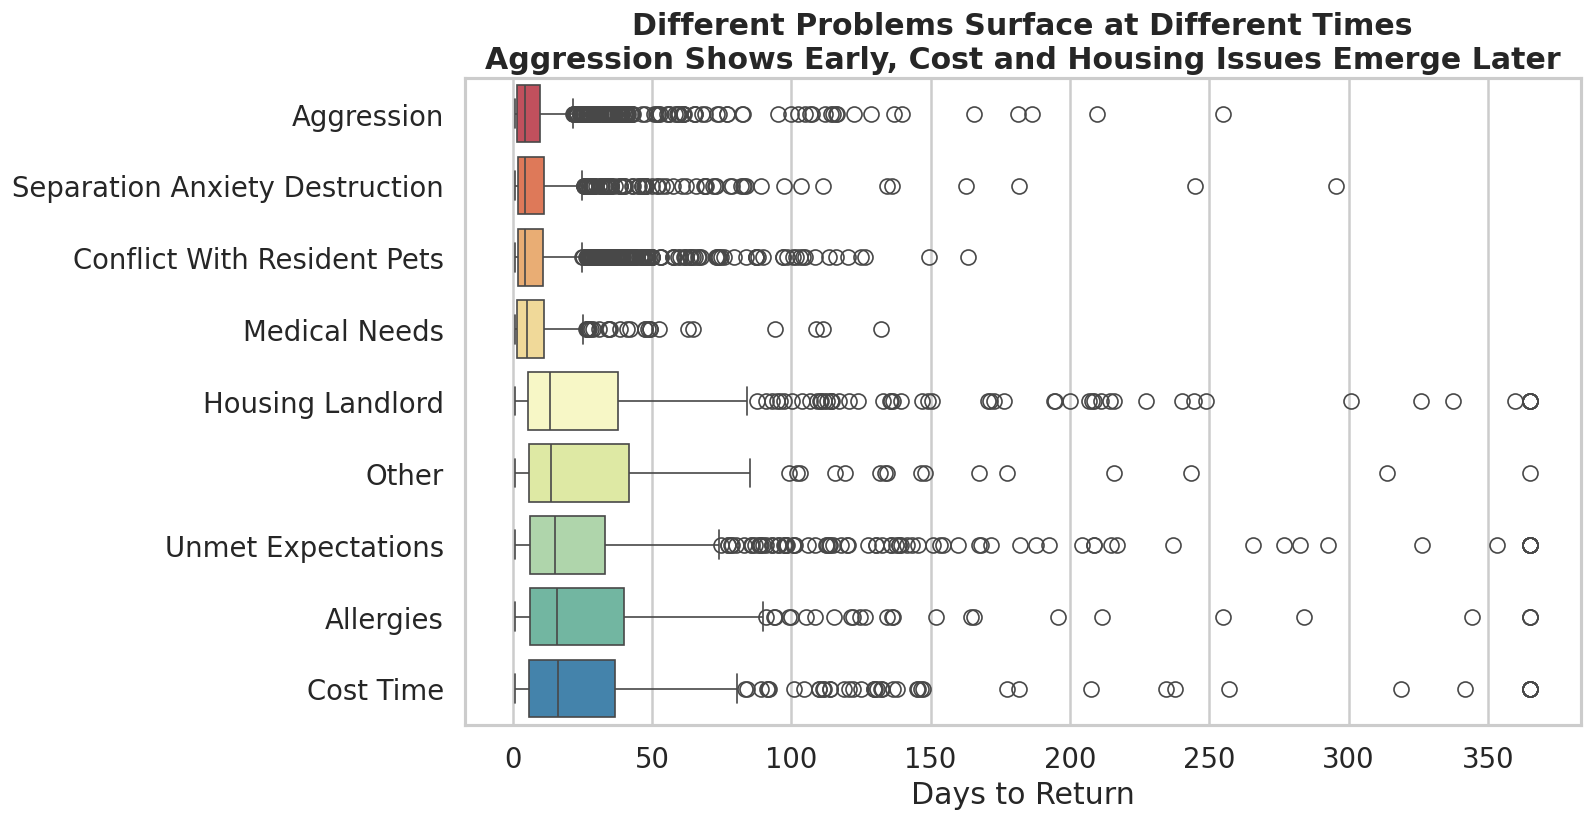

In [ ]:
sub = df[df.returned == 1].copy()
sub["return_reason"] = sub["return_reason"].str.replace("_", " ").str.title()
order = sub.groupby("return_reason")["days_to_return"].median().sort_values().index

fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(data=sub, y="return_reason", x="days_to_return", order=order,
            palette="Spectral", ax=ax)
ax.set_xlabel("Days to Return"); ax.set_ylabel("")
ax.set_title("Different Problems Surface at Different Times\n"
             "Aggression Shows Early, Cost and Housing Issues Emerge Later")
show(fig, "11_reason_vs_timing")

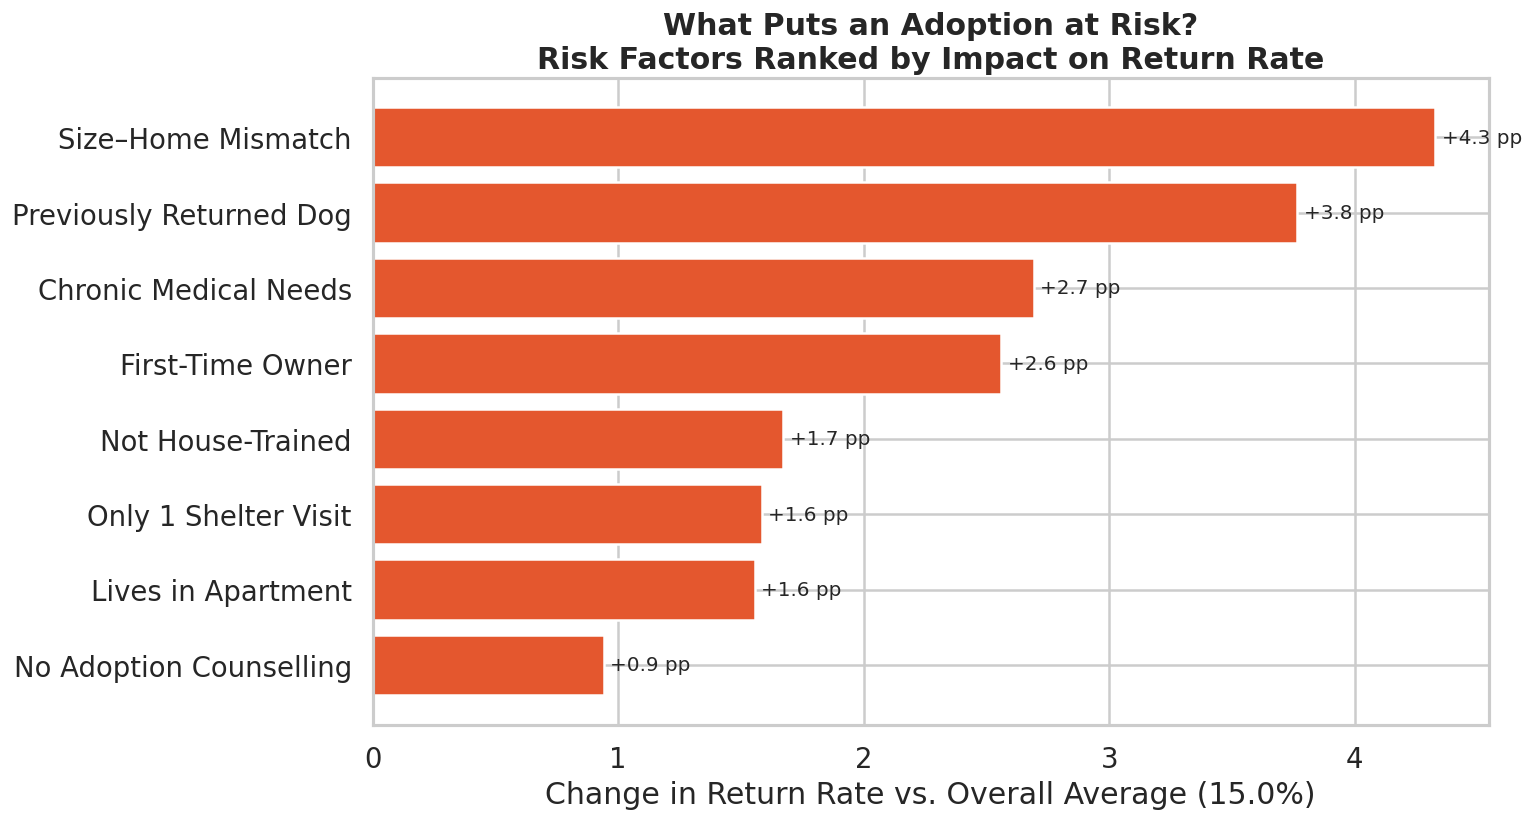

In [ ]:
factors = {
    "Previously Returned Dog": ("previously_returned", 1),
    "First-Time Owner": ("first_time_owner", 1),
    "Size–Home Mismatch": ("size_home_mismatch", 1),
    "Lives in Apartment": ("home_type", "apartment"),
    "Chronic Medical Needs": ("medical_needs", "chronic"),
    "Only 1 Shelter Visit": ("visits_before_adoption", 1),
    "No Adoption Counselling": ("adoption_counseling", 0),
    "Not House-Trained": ("house_trained", 0),
}
rows = []
for label, (col, val) in factors.items():
    r = df.loc[df[col] == val, "returned"].mean() * 100
    rows.append((label, r, r - BASE))
imp = pd.DataFrame(rows, columns=["Factor", "Rate", "Lift"]).sort_values("Lift")

fig, ax = plt.subplots(figsize=(12, 7))
colors = [PALETTE["returned"] if v > 0 else PALETTE["kept"] for v in imp["Lift"]]
bars = ax.barh(imp["Factor"], imp["Lift"], color=colors)
ax.bar_label(bars, fmt="%+.1f pp", padding=4, fontsize=12)
ax.axvline(0, c="black", lw=1)
ax.set_xlabel(f"Change in Return Rate vs. Overall Average ({BASE:.1f}%)")
ax.set_title("What Puts an Adoption at Risk?\n"
             "Risk Factors Ranked by Impact on Return Rate")
show(fig, "12_risk_factor_summary")

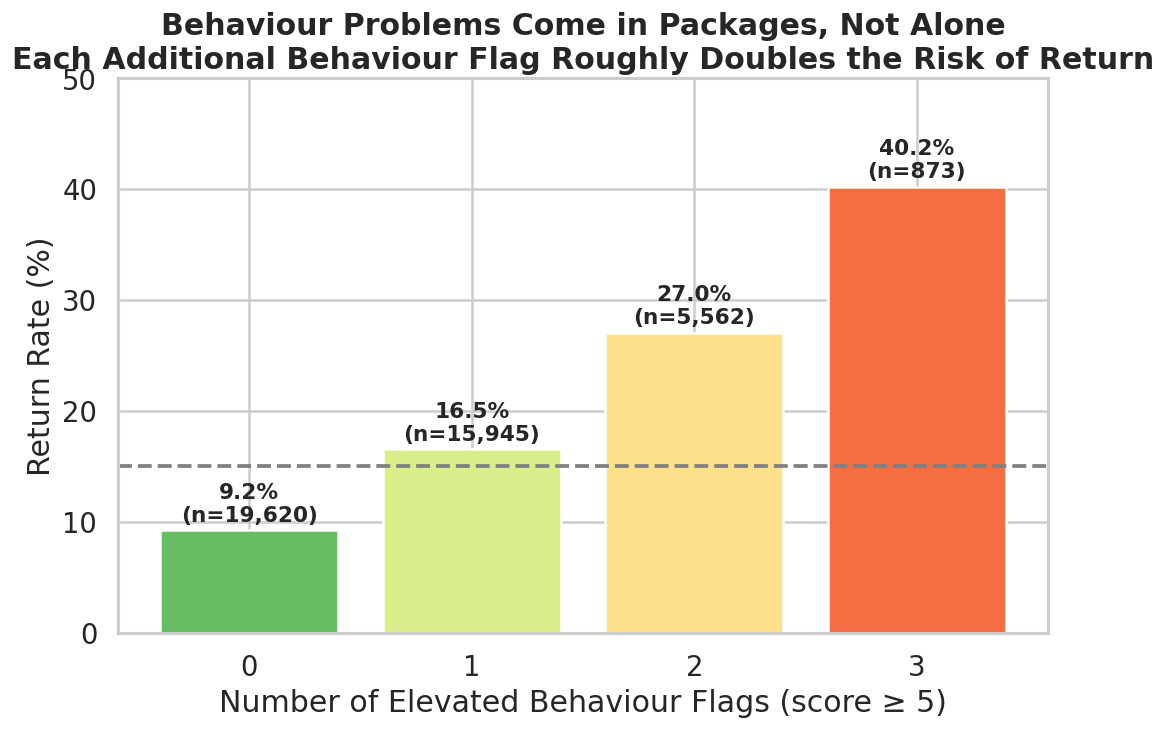

In [ ]:
df["n_flags"] = ((df.aggression_score >= 5).astype(int)
               + (df.anxiety_separation >= 5).astype(int)
               + (df.reactivity_to_dogs >= 5).astype(int))
b = df.groupby("n_flags")["returned"].agg(["mean", "size"])
b["mean"] *= 100

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(b.index.astype(str), b["mean"],
              color=sns.color_palette("RdYlGn_r", 4))
for bar, (rate, n) in zip(bars, b.values):
    ax.text(bar.get_x() + bar.get_width()/2, rate + .8,
            f"{rate:.1f}%\n(n={int(n):,})", ha="center",
            fontsize=13, fontweight="bold")
ax.axhline(BASE, ls="--", c="grey")
ax.set_xlabel("Number of Elevated Behaviour Flags (score ≥ 5)")
ax.set_ylabel("Return Rate (%)"); ax.set_ylim(0, 50)
ax.set_title("Behaviour Problems Come in Packages, Not Alone\n"
             "Each Additional Behaviour Flag Roughly Doubles the Risk of Return")
plt.savefig("14_behaviour_burden.png"); plt.show()

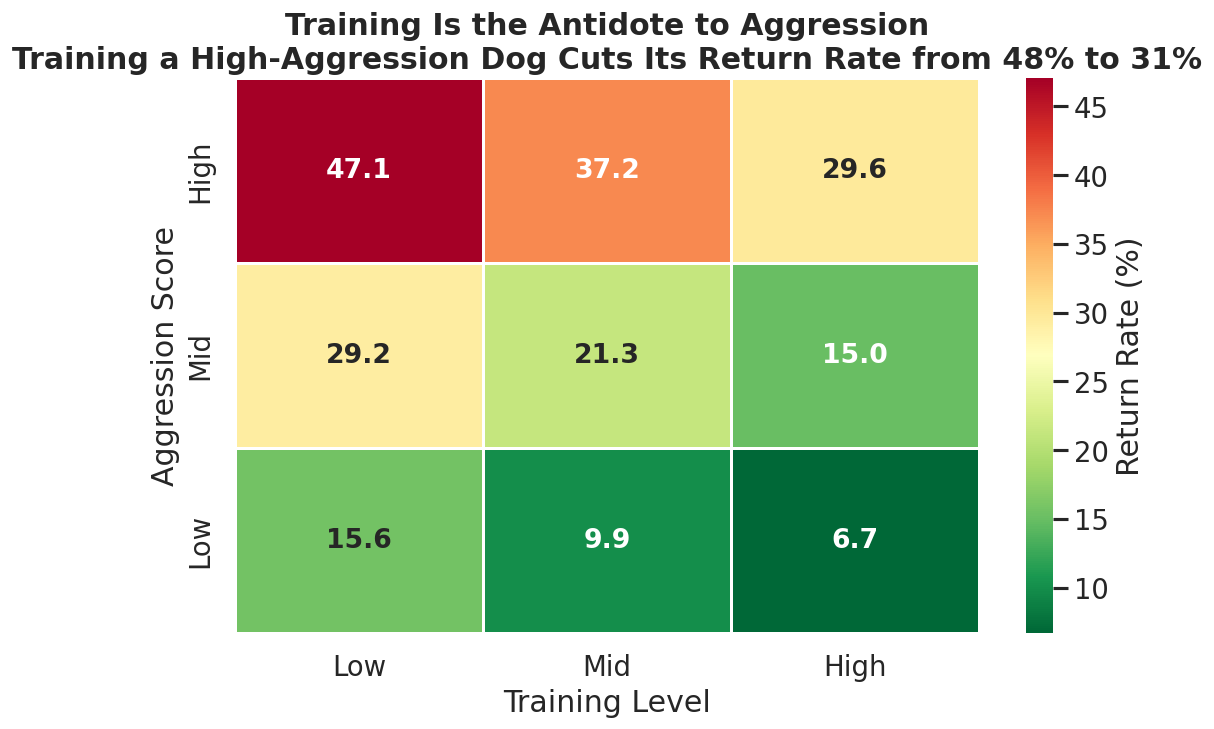

In [ ]:
df["tr_bin"]  = pd.cut(df.training_level,   [-.1,3,6,10], labels=["Low","Mid","High"])
df["agg_bin"] = pd.cut(df.aggression_score, [-.1,3,6,10], labels=["Low","Mid","High"])
p = (df.pivot_table(index="agg_bin", columns="tr_bin",
                    values="returned", aggfunc="mean", observed=True)*100
    ).reindex(["High","Mid","Low"])

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(p, annot=True, fmt=".1f", cmap="RdYlGn_r", linewidths=.8, ax=ax,
            annot_kws={"size":16,"weight":"bold"}, cbar_kws={"label":"Return Rate (%)"})
ax.set_xlabel("Training Level"); ax.set_ylabel("Aggression Score")
ax.set_title("Training Is the Antidote to Aggression\n"
             "Training a High-Aggression Dog Cuts Its Return Rate from 48% to 31%")
plt.savefig("15_training_buffer.png"); plt.show()

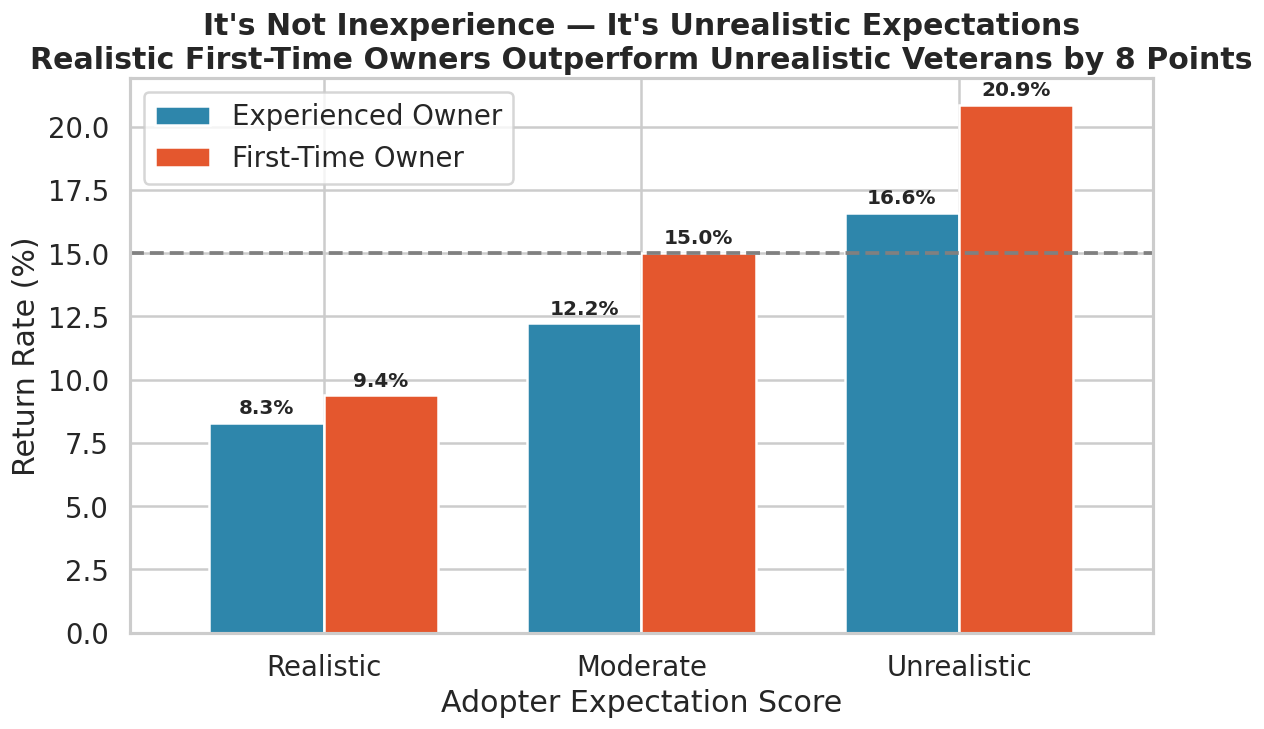

In [ ]:
df["exp_bin"] = pd.cut(df.expectation_score, [-.1,4,7,10],
                       labels=["Realistic","Moderate","Unrealistic"])
m = (df.groupby(["exp_bin","first_time_owner"], observed=True)["returned"]
       .mean().mul(100).unstack())
m.columns = ["Experienced Owner", "First-Time Owner"]

fig, ax = plt.subplots(figsize=(11, 6))
m.plot(kind="bar", ax=ax, color=[PALETTE["kept"], PALETTE["returned"]],
       rot=0, width=.72, edgecolor="white")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=3, fontsize=12, fontweight="bold")
ax.axhline(BASE, ls="--", c="grey")
ax.set_xlabel("Adopter Expectation Score"); ax.set_ylabel("Return Rate (%)")
ax.legend(title="")
ax.set_title("It's Not Inexperience — It's Unrealistic Expectations\n"
             "Realistic First-Time Owners Outperform Unrealistic Veterans by 8 Points")
plt.savefig("16_expectation_mediation.png"); plt.show()

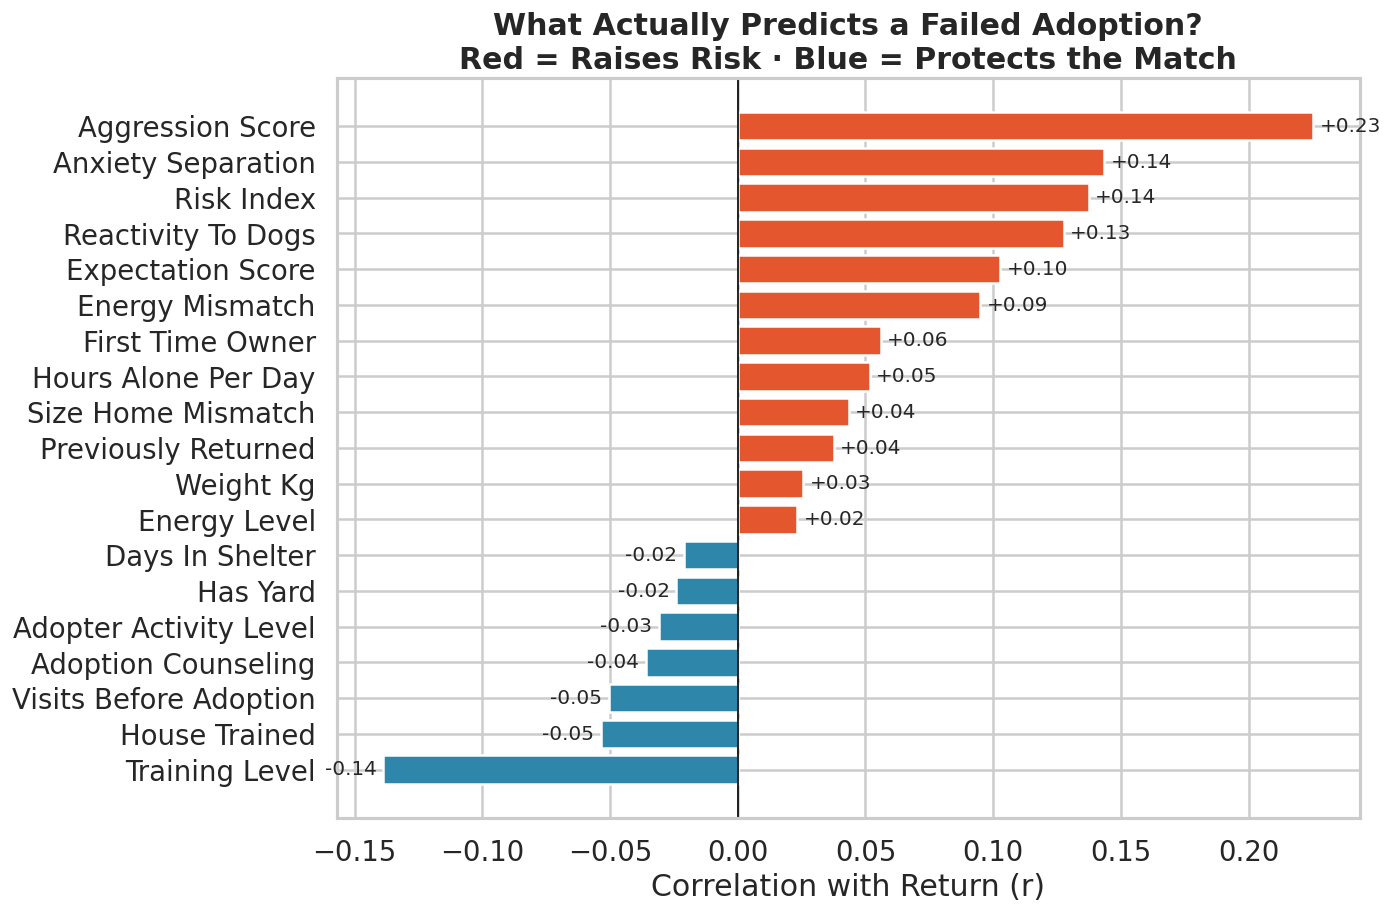

In [ ]:
num = df.select_dtypes("number").drop(columns=["returned","days_to_return"], errors="ignore")
corr = num.corrwith(df["returned"]).drop(labels=[c for c in
        ["n_flags"] if c in num.columns], errors="ignore")
corr = corr[corr.abs() > .02].sort_values()

fig, ax = plt.subplots(figsize=(11, 8))
colors = [PALETTE["returned"] if v > 0 else PALETTE["kept"] for v in corr]
bars = ax.barh([i.replace("_"," ").title() for i in corr.index], corr.values, color=colors)
ax.bar_label(bars, fmt="%+.2f", padding=4, fontsize=12)
ax.axvline(0, c="black", lw=1)
ax.set_xlabel("Correlation with Return (r)")
ax.set_title("What Actually Predicts a Failed Adoption?\n"
             "Red = Raises Risk · Blue = Protects the Match")
plt.savefig("19_correlation_tornado.png"); plt.show()